# OpenClassrooms - parcours Data Analyst Business Intelligence - P8

# Milestone 1 - Analyse des données

Dans cette partie, j’analyse le jeu de données disponible. Mon objectif est de comprendre les relations entre les variables, puis de conserver celles qui servent à l’apprentissage du modèle de prédiction.

## 1.Type des données

La première étape à réaliser est d'importer les données dans le notebook et d'opérer des transformations sur les variables si celles-ci s'imposent (exemple : nettoyage ou changement de type des variables, etc.).

In [2]:
# J'importe les librairies utilisées pour traiter les données et produire les visualisations.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Charte graphique du projet

Charte visuelle commune utilisée pour les visualisations :
- **Bleu nuit** : données observées / indicateurs principaux
- **Bleu-vert** : comparaisons et segments
- **Orange** : valeurs prédites
- **Rouge brique** : erreurs / écarts



In [3]:
# Charte graphique commune du projet
COULEUR_PRINCIPALE = "#1F4E78"   # bleu nuit
COULEUR_SECONDAIRE = "#2A9D8F"   # bleu-vert
COULEUR_PREDICTION = "#F4A261"   # orange
COULEUR_ERREUR = "#C75C5C"       # rouge brique
COULEUR_GRILLE = "#D9E2EC"

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#B8C2CC",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.color": COULEUR_GRILLE,
    "grid.alpha": 0.55,
    "grid.linestyle": "--",
    "axes.axisbelow": True,
    "legend.frameon": False,
    "font.size": 10
})


In [4]:
# Le moteur openpyxl est utilisé par pandas pour lire les fichiers Excel du projet.


In [5]:
# J'importe les trois fichiers Excel placés dans le même dossier que le notebook.
DOSSIER_PROJET = Path.cwd()

chemin_echantillon = DOSSIER_PROJET / "echantillon_a_classer2.xlsx"
chemin_historique = DOSSIER_PROJET / "historique_immobilier_paris_2017_2021_vdef2.xlsx"
chemin_portefeuille = DOSSIER_PROJET / "portefeuille_actifs+(3).xlsx"

df_sample = pd.read_excel(chemin_echantillon, engine="openpyxl")
df_history = pd.read_excel(chemin_historique, engine="openpyxl")
df_wallet = pd.read_excel(chemin_portefeuille, engine="openpyxl")


Les données sont chargées depuis des chemins relatifs. Le notebook peut donc être exécuté directement depuis le dossier du projet, sans dépendre d’un chemin local Windows.

In [6]:
# Je vérifie que le type des données attribué par pandas est cohérent.
display(df_sample.dtypes)
display(df_history.dtypes)
display(df_wallet.dtypes)


valeur_fonciere    float64
code_postal          int64
nom_commune         object
surface_reelle       int64
dtype: object

date_mutation       datetime64[ns]
valeur_fonciere            float64
adresse_numero               int64
adresse_nom_voie            object
code_postal                  int64
nom_commune                 object
code_type_local              int64
type_local                  object
surface_reelle               int64
dtype: object

adresse_numero                 int64
adresse_nom_voie              object
code_postal                    int64
code_commune                   int64
nom_commune                   object
surface_carrez               float64
code_type_local                int64
type_local                    object
surface_reelle_bati            int64
nombre_pieces_principales      int64
longitude                    float64
latitude                     float64
dtype: object

In [7]:
display(df_sample.head())
display(df_history.head())
display(df_wallet.head())


,valeur_fonciere,code_postal,nom_commune,surface_reelle
0,868687.083271,75019,Paris 19e Arrondissement,88
1,452050.762192,75019,Paris 19e Arrondissement,45
2,193088.653587,75019,Paris 19e Arrondissement,21
3,303012.549370,75019,Paris 19e Arrondissement,32
4,149272.200110,75019,Paris 19e Arrondissement,20


,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle
0,2017-01-03,5.505597e+05,8,RUE DES COUTURES SAINT GERVAIS,75003,Paris 3e Arrondissement,2,Appartement,50
1,2017-01-12,1.576492e+06,32,AV MARCEAU,75008,Paris 8e Arrondissement,2,Appartement,163
2,2017-01-10,6.577574e+05,52,RUE DU FAUBOURG SAINT HONORE,75008,Paris 8e Arrondissement,2,Appartement,66
3,2017-01-10,2.500868e+05,64,RUE DU VERTBOIS,75003,Paris 3e Arrondissement,2,Appartement,22
4,2017-01-13,1.762667e+05,25,RUE DES LAVANDIERES STE OPPORT,75001,Paris 1er Arrondissement,2,Appartement,15


,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,surface_carrez,code_type_local,type_local,surface_reelle_bati,nombre_pieces_principales,longitude,latitude
0,127,RUE SAINT-DENIS,75001,75101,Paris 1er Arrondissement,16.41,2,Appartement,25,1,2.349593,48.863227
1,62,RUE NOTRE-DAME DE NAZARETH,75003,75103,Paris 3e Arrondissement,20.47,2,Appartement,22,1,2.356977,48.867907
2,62,RUE DE TURENNE,75003,75103,Paris 3e Arrondissement,64.48,2,Appartement,65,3,2.364855,48.859318
3,32,AV GEORGE V,75008,75108,Paris 8e Arrondissement,63.29,2,Appartement,74,2,2.301586,48.868893
4,152,BD HAUSSMANN,75008,75108,Paris 8e Arrondissement,20.58,2,Appartement,22,1,2.311643,48.875490


In [8]:
display(df_history["valeur_fonciere"].describe())

count    2.619600e+04
mean     4.916170e+05
std      5.713292e+05
min      8.519470e+04
25%      2.339439e+05
50%      3.545774e+05
75%      5.702197e+05
max      3.843359e+07
Name: valeur_fonciere, dtype: float64

In [9]:
pd.set_option("display.float_format", "{:,.2f}".format)
display(df_sample.head())
display(df_history.head())
display(df_wallet.head())

,valeur_fonciere,code_postal,nom_commune,surface_reelle
0,"868,687.08",75019,Paris 19e Arrondissement,88
1,"452,050.76",75019,Paris 19e Arrondissement,45
2,"193,088.65",75019,Paris 19e Arrondissement,21
3,"303,012.55",75019,Paris 19e Arrondissement,32
4,"149,272.20",75019,Paris 19e Arrondissement,20


,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle
0,2017-01-03,"550,559.68",8,RUE DES COUTURES SAINT GERVAIS,75003,Paris 3e Arrondissement,2,Appartement,50
1,2017-01-12,"1,576,492.46",32,AV MARCEAU,75008,Paris 8e Arrondissement,2,Appartement,163
2,2017-01-10,"657,757.36",52,RUE DU FAUBOURG SAINT HONORE,75008,Paris 8e Arrondissement,2,Appartement,66
3,2017-01-10,"250,086.82",64,RUE DU VERTBOIS,75003,Paris 3e Arrondissement,2,Appartement,22
4,2017-01-13,"176,266.71",25,RUE DES LAVANDIERES STE OPPORT,75001,Paris 1er Arrondissement,2,Appartement,15


,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,surface_carrez,code_type_local,type_local,surface_reelle_bati,nombre_pieces_principales,longitude,latitude
0,127,RUE SAINT-DENIS,75001,75101,Paris 1er Arrondissement,16.41,2,Appartement,25,1,2.35,48.86
1,62,RUE NOTRE-DAME DE NAZARETH,75003,75103,Paris 3e Arrondissement,20.47,2,Appartement,22,1,2.36,48.87
2,62,RUE DE TURENNE,75003,75103,Paris 3e Arrondissement,64.48,2,Appartement,65,3,2.36,48.86
3,32,AV GEORGE V,75008,75108,Paris 8e Arrondissement,63.29,2,Appartement,74,2,2.30,48.87
4,152,BD HAUSSMANN,75008,75108,Paris 8e Arrondissement,20.58,2,Appartement,22,1,2.31,48.88


## Contrôle qualité des données avant analyse

### DataFrame Histo

In [10]:
# Vérification des valeurs manquantes
display(df_history.isna().sum())

date_mutation       0
valeur_fonciere     0
adresse_numero      0
adresse_nom_voie    0
code_postal         0
nom_commune         0
code_type_local     0
type_local          0
surface_reelle      0
dtype: int64

In [11]:
# Vérification des doublons complets
nb_doublons = df_history.duplicated().sum()

print("Nombre de doublons complets :", nb_doublons)

Nombre de doublons complets : 16


In [12]:
# Afficher toutes les lignes concernées par des doublons complets
df_history_duplicates = df_history[df_history.duplicated(keep=False)]

display(df_history_duplicates.sort_values(["date_mutation", "valeur_fonciere", "surface_reelle"]))

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle
2768,2017-01-04,"885,116.63",8,RUE PAUL HERVIEU,75015,Paris 15e Arrondissement,2,Appartement,98
2775,2017-01-04,"885,116.63",8,RUE PAUL HERVIEU,75015,Paris 15e Arrondissement,2,Appartement,98
3435,2017-05-16,"108,677.31",7,RUE DOCTEUR GERMAIN SEE,75016,Paris 16e Arrondissement,2,Appartement,11
3436,2017-05-16,"108,677.31",7,RUE DOCTEUR GERMAIN SEE,75016,Paris 16e Arrondissement,2,Appartement,11
196,2017-05-18,"246,703.32",400,RUE SAINT HONORE,75001,Paris 1er Arrondissement,4,Local industriel. commercial ou assimilé,19
209,2017-05-18,"246,703.32",400,RUE SAINT HONORE,75001,Paris 1er Arrondissement,4,Local industriel. commercial ou assimilé,19
375,2017-10-17,"855,144.86",71,RUE D AMSTERDAM,75008,Paris 8e Arrondissement,2,Appartement,82
376,2017-10-17,"855,144.86",71,RUE D AMSTERDAM,75008,Paris 8e Arrondissement,2,Appartement,82
4755,2017-12-20,"132,855.44",18,RUE SIMART,75018,Paris 18e Arrondissement,2,Appartement,15
4756,2017-12-20,"132,855.44",18,RUE SIMART,75018,Paris 18e Arrondissement,2,Appartement,15


In [13]:
df_history_clean = df_history.drop_duplicates().copy()

print("Nombre de lignes avant suppression :", len(df_history))
print("Nombre de lignes après suppression :", len(df_history_clean))
print("Nombre de lignes supprimées :", len(df_history) - len(df_history_clean))

Nombre de lignes avant suppression : 26196
Nombre de lignes après suppression : 26180
Nombre de lignes supprimées : 16


In [14]:
# Vérification des surfaces nulles ou négatives
display(df_history_clean[df_history_clean["surface_reelle"] <= 0])

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle


In [15]:
# Vérification des valeurs foncières nulles ou négatives
display(df_history_clean[df_history_clean["valeur_fonciere"] <= 0])

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle


In [16]:
# Vérification des types de biens disponibles
display(df_history_clean["type_local"].value_counts(dropna=False))

type_local
Appartement                                 24338
Local industriel. commercial ou assimilé     1842
Name: count, dtype: int64

### DataFrame PF

In [17]:
# Vérification des valeurs manquantes
display(df_wallet.isna().sum())

adresse_numero               0
adresse_nom_voie             0
code_postal                  0
code_commune                 0
nom_commune                  0
surface_carrez               0
code_type_local              0
type_local                   0
surface_reelle_bati          0
nombre_pieces_principales    0
longitude                    0
latitude                     0
dtype: int64

In [18]:
# Vérification des doublons complets
nb_doublons = df_wallet.duplicated().sum()

print("Nombre de doublons complets :", nb_doublons)

Nombre de doublons complets : 2


In [19]:
# Afficher toutes les lignes concernées par des doublons complets
df_wallet_duplicates = df_wallet[df_wallet.duplicated(keep=False)]

display(df_wallet_duplicates.sort_values(["code_postal", "nom_commune", "adresse_nom_voie", "adresse_numero", "type_local", "surface_reelle_bati"]))

,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,surface_carrez,code_type_local,type_local,surface_reelle_bati,nombre_pieces_principales,longitude,latitude
249,104,BD VOLTAIRE,75011,75111,Paris 11e Arrondissement,38.50,4,Local industriel. commercial ou assimilé,42,0,2.38,48.86
250,104,BD VOLTAIRE,75011,75111,Paris 11e Arrondissement,38.50,4,Local industriel. commercial ou assimilé,42,0,2.38,48.86
166,3,RUE DAMREMONT,75018,75118,Paris 18e Arrondissement,26.86,4,Local industriel. commercial ou assimilé,27,0,2.33,48.89
185,3,RUE DAMREMONT,75018,75118,Paris 18e Arrondissement,26.86,4,Local industriel. commercial ou assimilé,27,0,2.33,48.89


In [20]:
df_wallet_clean = df_wallet.drop_duplicates().copy()

print("Nombre de lignes avant suppression :", len(df_wallet))
print("Nombre de lignes après suppression :", len(df_wallet_clean))
print("Nombre de lignes supprimées :", len(df_wallet) - len(df_wallet_clean))

Nombre de lignes avant suppression : 275
Nombre de lignes après suppression : 273
Nombre de lignes supprimées : 2


In [21]:
### Changer le type de `code_postal` ? de int64  à String ? idem `code_commune`,`code_tye_local` OUI ! Attention dépa lettre
### df_history_clean["code_postal"] = df_history_clean["code_postal"].astype(str)
### df_wallet["code_postal"] = df_wallet["code_postal"].astype(str)
### df_sample["code_postal"] = df_sample["code_postal"].astype(str)

In [22]:
display(df_history_clean['type_local'].unique())
display(df_history_clean['code_type_local'].unique())
display(df_wallet_clean['type_local'].unique())
display(df_wallet_clean['code_type_local'].unique())

array(['Appartement', 'Local industriel. commercial ou assimilé'],
      dtype=object)

array([2, 4])

array(['Appartement', 'Local industriel. commercial ou assimilé'],
      dtype=object)

array([2, 4])

### 2. Observation des différents types de biens immobiliers présents dans les données

In [23]:
print("Liste des types de biens immobiliers présents dans les données :", df_wallet_clean["type_local"].unique())


Liste des types de biens immobiliers présents dans les données : ['Appartement' 'Local industriel. commercial ou assimilé']


J’observe 2 types de biens dans les données : appartements et locaux industriels, commerciaux ou assimilés. Leurs codes types sont 2 et 4.

### 3. Nombre de transactions

In [24]:
nb_transactions = len(df_history_clean)

nb_appartements = (df_history_clean["type_local"] == "Appartement").sum()

nb_locaux = (df_history_clean["type_local"] == "Local industriel. commercial ou assimilé").sum()

# Je vérifie le nombre de transactions dans le dataframe.
print("Le nombre de transactions dans les données est :", nb_transactions)
print("Le nombre de transactions pour les appartements est :", nb_appartements)
print("Le nombre de transactions pour les locaux commerciaux est :", nb_locaux)


Le nombre de transactions dans les données est : 26180
Le nombre de transactions pour les appartements est : 24338
Le nombre de transactions pour les locaux commerciaux est : 1842


### 4. interval de l'historique des données

In [25]:
first = df_history_clean["date_mutation"].min()
last = df_history_clean["date_mutation"].max()
# Je vérifie également la plage de l'historique disponible
print('la première date de transaction dans les données est le', first.date())
print('la dernière date de transaction dans les données est le', last.date())

la première date de transaction dans les données est le 2017-01-02
la dernière date de transaction dans les données est le 2021-12-31


## Commençons à analyser les données

J’analyse maintenant les données historiques pour les deux types de biens immobiliers. Afin de comparer les biens entre eux, je crée une colonne de prix au mètre carré.

In [26]:
display(df_history_clean[df_history_clean["surface_reelle"] <= 0])
# Calcul de la colonne valeur foncière / surface réelle
df_history_clean["prix_au_m2"] = df_history_clean["valeur_fonciere"] / df_history_clean["surface_reelle"]
display(df_history_clean[["valeur_fonciere", "surface_reelle", "prix_au_m2"]].head())

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle


,valeur_fonciere,surface_reelle,prix_au_m2
0,"550,559.68",50,"11,011.19"
1,"1,576,492.46",163,"9,671.73"
2,"657,757.36",66,"9,966.02"
3,"250,086.82",22,"11,367.58"
4,"176,266.71",15,"11,751.11"


Maintenant, analysons les appartements.

### 5. Evolution du prix au metre carré des appartements dans Paris

In [27]:
# Je retire les colonnes qui sont à priori inutiles ET Je vais je concentrer sur les appartements dans un premier temps
df_apartment_history = df_history_clean[["date_mutation","valeur_fonciere","type_local","surface_reelle","prix_au_m2"]].copy()
display(df_apartment_history.head())

,date_mutation,valeur_fonciere,type_local,surface_reelle,prix_au_m2
0,2017-01-03,"550,559.68",Appartement,50,"11,011.19"
1,2017-01-12,"1,576,492.46",Appartement,163,"9,671.73"
2,2017-01-10,"657,757.36",Appartement,66,"9,966.02"
3,2017-01-10,"250,086.82",Appartement,22,"11,367.58"
4,2017-01-13,"176,266.71",Appartement,15,"11,751.11"


In [28]:
df_apartment_history = df_apartment_history[df_apartment_history["type_local"] == "Appartement"].copy()
display(df_apartment_history.head())

,date_mutation,valeur_fonciere,type_local,surface_reelle,prix_au_m2
0,2017-01-03,"550,559.68",Appartement,50,"11,011.19"
1,2017-01-12,"1,576,492.46",Appartement,163,"9,671.73"
2,2017-01-10,"657,757.36",Appartement,66,"9,966.02"
3,2017-01-10,"250,086.82",Appartement,22,"11,367.58"
4,2017-01-13,"176,266.71",Appartement,15,"11,751.11"


In [29]:
#Préparons un dataframe en regroupant les prix moyens de ventes des appartements par année avec la surface moyenne associée
df_apartment_history["annee"] = df_apartment_history["date_mutation"].dt.year

df_apartment_evolution = df_apartment_history.groupby("annee").agg(
    prix_moyen_m2=("prix_au_m2", "mean"), 
    surface_moyenne=("surface_reelle","mean"),
    nb_transcations=("prix_au_m2","count")
    ).reset_index()

display(df_apartment_evolution)

,annee,prix_moyen_m2,surface_moyenne,nb_transcations
0,2017,"9,492.44",44.63,5201
1,2018,"10,031.40",44.27,5076
2,2019,"10,562.46",43.37,5245
3,2020,"10,675.34",42.91,4123
4,2021,"10,455.60",43.48,4693


Sur la période 2017-2021, le prix moyen au mètre carré des appartements parisiens augmente globalement, passant d’environ 9 492 €/m² à 10 456 €/m². La hausse est continue jusqu’en 2020, puis une légère baisse apparaît en 2021. En parallèle, le nombre de transactions diminue globalement, avec une baisse marquée en 2020 puis une reprise partielle en 2021. La surface moyenne reste assez stable, autour de 43 à 45 m². <br>

Je vais créer un graphique pour mieux le visualiser.

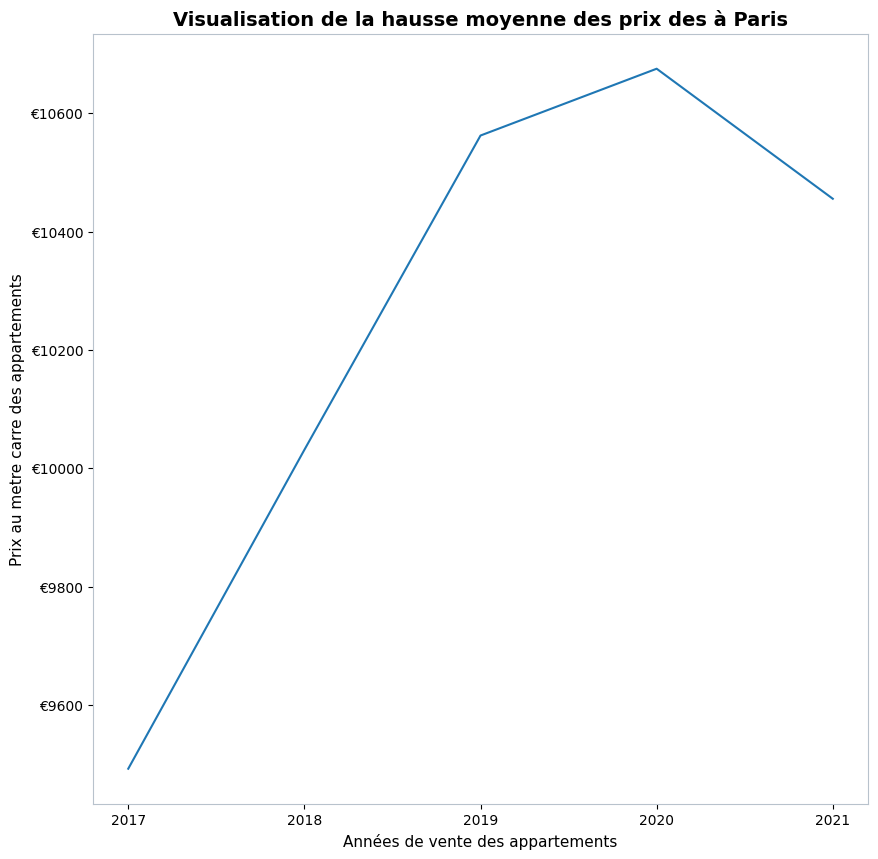

In [30]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.figure(figsize=(10,10))
plt.plot(df_apartment_evolution["annee"],df_apartment_evolution["prix_moyen_m2"] )
plt.xlabel('Années de vente des appartements')
plt.ylabel('Prix au metre carre des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)

plt.xticks(df_apartment_evolution["annee"])
plt.grid()
plt.title('Visualisation de la hausse moyenne des prix des à Paris')
plt.show()

### 6. Différences de prix au metre carré entre les arrondissements

Maintenant Je vais chercher à afficher l'évolution des prix par arrondissement. Vérifions la liste des arrondissements que J'ai dans mes données. Normalement à Paris J'ai 20 codes postaux différents, 1 par arrondissement allant de 75001 à 75020.

In [31]:
df_apartment_history = df_history_clean[
    [
        "date_mutation",
        "valeur_fonciere",
        "code_postal",
        "nom_commune",
        "type_local",
        "surface_reelle",
        "prix_au_m2"
    ]
].copy()

df_apartment_history = df_apartment_history[
    df_apartment_history["type_local"] == "Appartement"
].copy()

display(df_apartment_history.head())

,date_mutation,valeur_fonciere,code_postal,nom_commune,type_local,surface_reelle,prix_au_m2
0,2017-01-03,"550,559.68",75003,Paris 3e Arrondissement,Appartement,50,"11,011.19"
1,2017-01-12,"1,576,492.46",75008,Paris 8e Arrondissement,Appartement,163,"9,671.73"
2,2017-01-10,"657,757.36",75008,Paris 8e Arrondissement,Appartement,66,"9,966.02"
3,2017-01-10,"250,086.82",75003,Paris 3e Arrondissement,Appartement,22,"11,367.58"
4,2017-01-13,"176,266.71",75001,Paris 1er Arrondissement,Appartement,15,"11,751.11"


In [32]:
#Liste des codes postaux dans mes données.
df_apartment_history["code_postal"].sort_values().unique()

array([75001, 75002, 75003, 75004, 75005, 75006, 75007, 75008, 75009,
       75010, 75011, 75012, 75013, 75014, 75015, 75016, 75017, 75018,
       75019, 75020])

In [33]:
#Créeons un dataframe pour une deuxième visualisation avec l'evolution des prix par arrondissement
df_district_prices = df_apartment_history.groupby("code_postal").agg(
    prix_moyen_m2=("prix_au_m2", "mean"),
    nb_transactions=("prix_au_m2", "count")
).reset_index()

In [34]:
# Filtrer uniquement le 1er arrondissement
df_apartments_75001 = df_apartment_history[
    df_apartment_history["code_postal"] == 75001
].copy()

# Créer la colonne année
df_apartments_75001["annee"] = df_apartments_75001["date_mutation"].dt.year

# Regrouper par année
df_prices_75001 = df_apartments_75001.groupby("annee").agg(
    prix_moyen_m2=("prix_au_m2", "mean")
).reset_index()

display(df_prices_75001)

,annee,prix_moyen_m2
0,2017,"11,762.71"
1,2018,"12,621.23"
2,2019,"13,269.26"
3,2020,"13,405.99"
4,2021,"13,379.50"


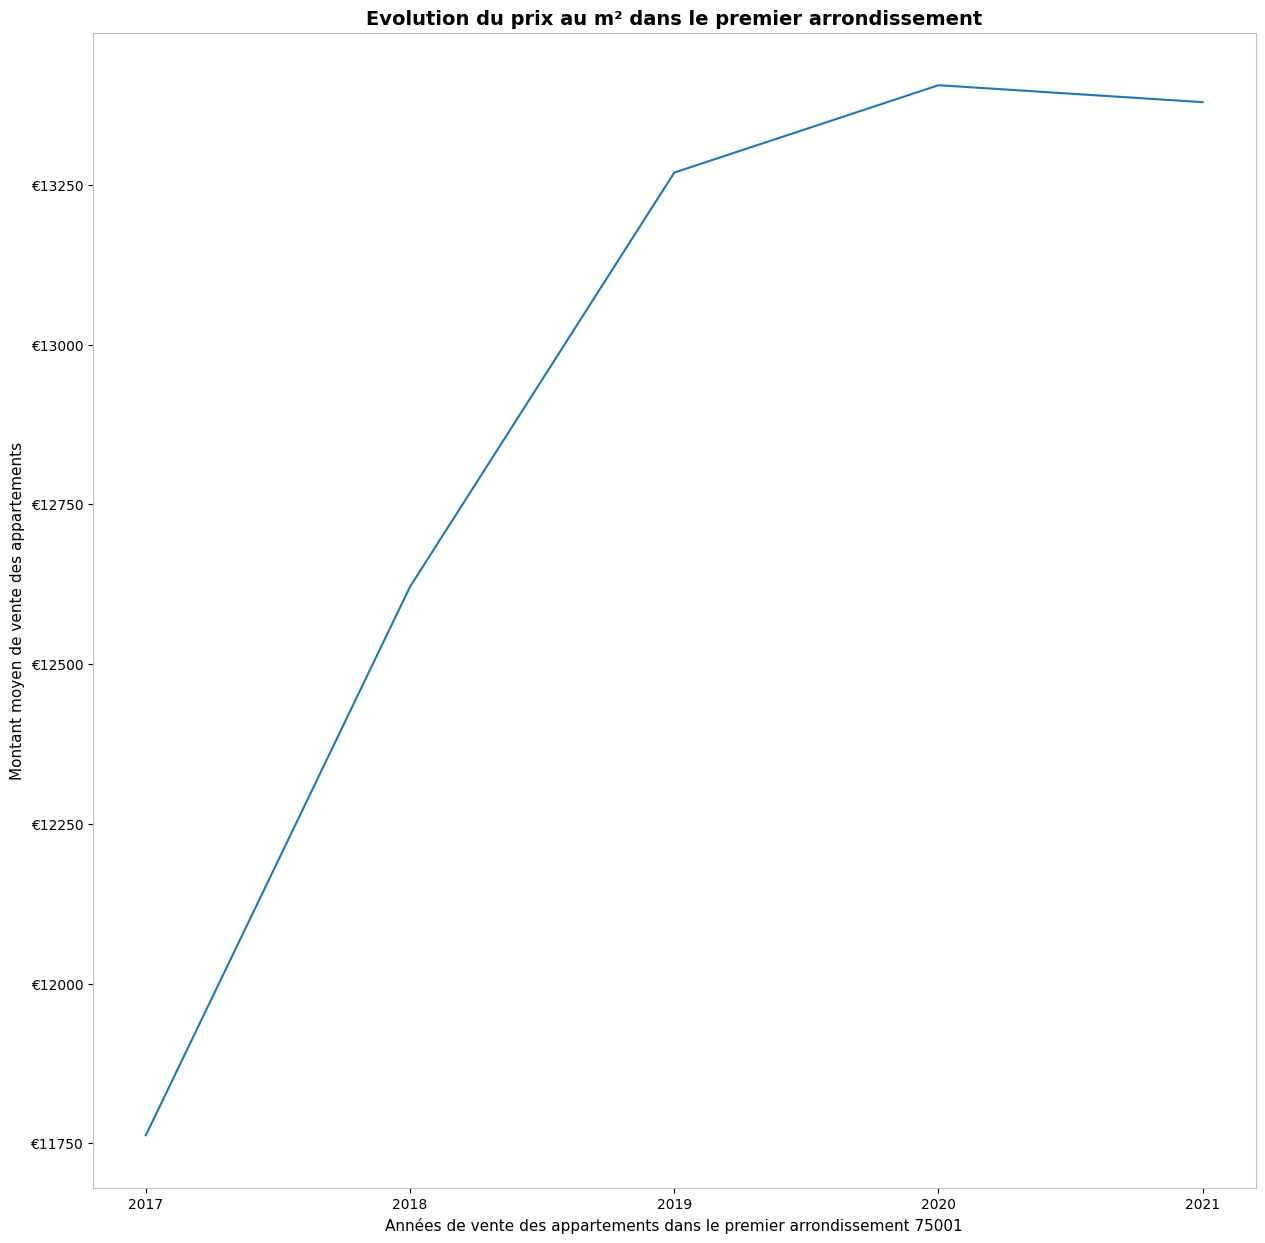

In [35]:
#Création d'un graphique pour visualiser la hausse de la moyenne des prix au metre carré dans le premier arrondissement
plt.figure(figsize=(15,15))
plt.plot(df_prices_75001["annee"], df_prices_75001["prix_moyen_m2"])
plt.xlabel('Années de vente des appartements dans le premier arrondissement 75001')
plt.ylabel('Montant moyen de vente des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)
plt.xticks(df_apartment_evolution["annee"])
plt.grid()
plt.title('Evolution du prix au m² dans le premier arrondissement')
plt.show()

Je vais ajouter à cette visualisation tous les autres arrondissement avec une couleur différente.

In [36]:
# Création de l'année si elle n'existe pas déjà
df_apartment_history["annee"] = df_apartment_history["date_mutation"].dt.year

# Prix moyen au m² par année et par arrondissement
df_district_year_prices = df_apartment_history.groupby(
    ["annee", "code_postal"]
).agg(
    prix_moyen_m2=("prix_au_m2", "mean")
).reset_index()

display(df_district_year_prices.head())

,annee,code_postal,prix_moyen_m2
0,2017,75001,"11,762.71"
1,2017,75002,"10,920.13"
2,2017,75003,"11,679.82"
3,2017,75004,"12,407.23"
4,2017,75005,"11,306.20"


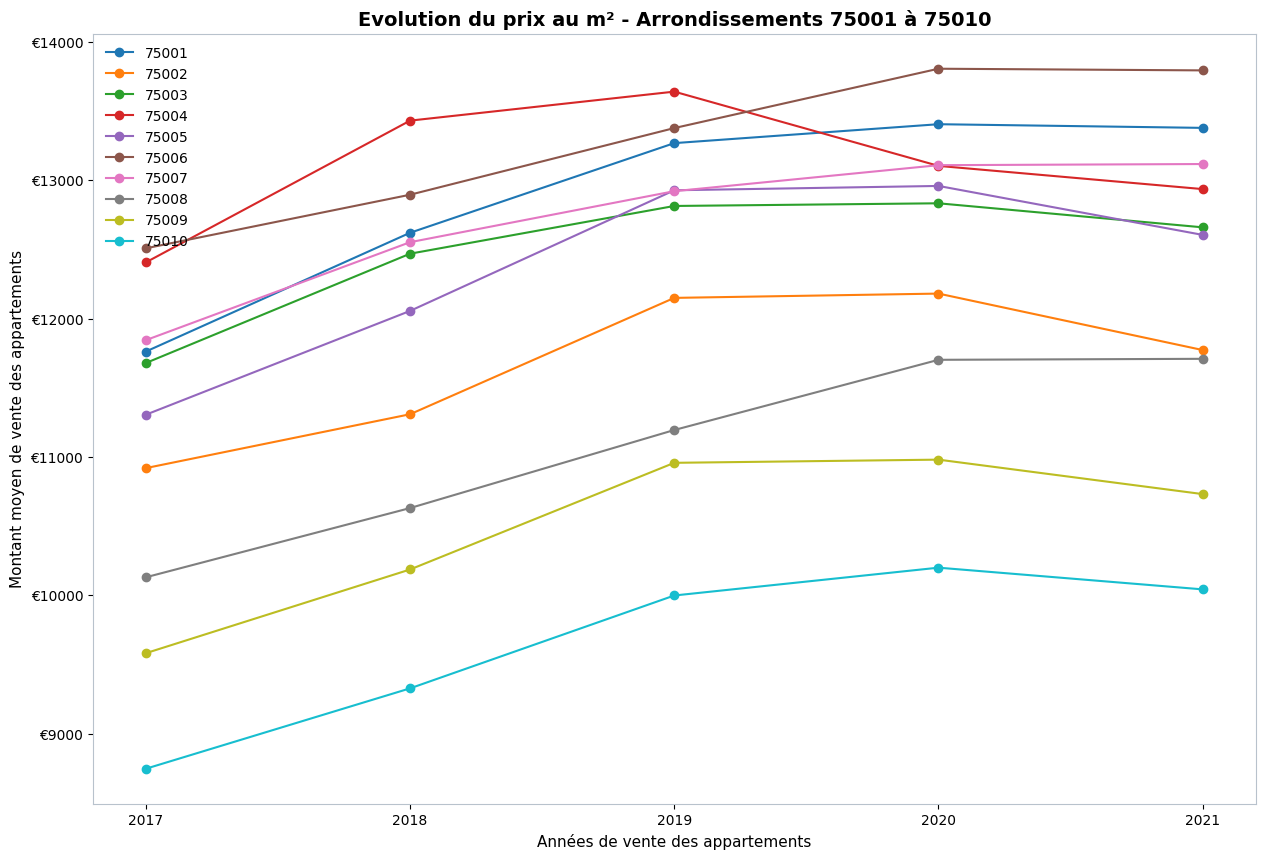

In [37]:
# J'affiche l'évolution du prix au m² pour les arrondissements 75001 à 75010
plt.figure(figsize=(15, 10))

for code_postal in range(75001, 75011):
    df_district_data = df_district_year_prices[
        df_district_year_prices["code_postal"] == code_postal
    ]

    plt.plot(
        df_district_data["annee"],
        df_district_data["prix_moyen_m2"],
        marker="o",
        label=str(code_postal)
    )

plt.xlabel("Années de vente des appartements")
plt.ylabel("Montant moyen de vente des appartements")
formatter = ticker.FormatStrFormatter("€%d")
plt.gca().yaxis.set_major_formatter(formatter)
plt.xticks(df_apartment_evolution["annee"])
plt.grid()
plt.title("Evolution du prix au m² - Arrondissements 75001 à 75010")
plt.legend(loc="upper left")
plt.show()


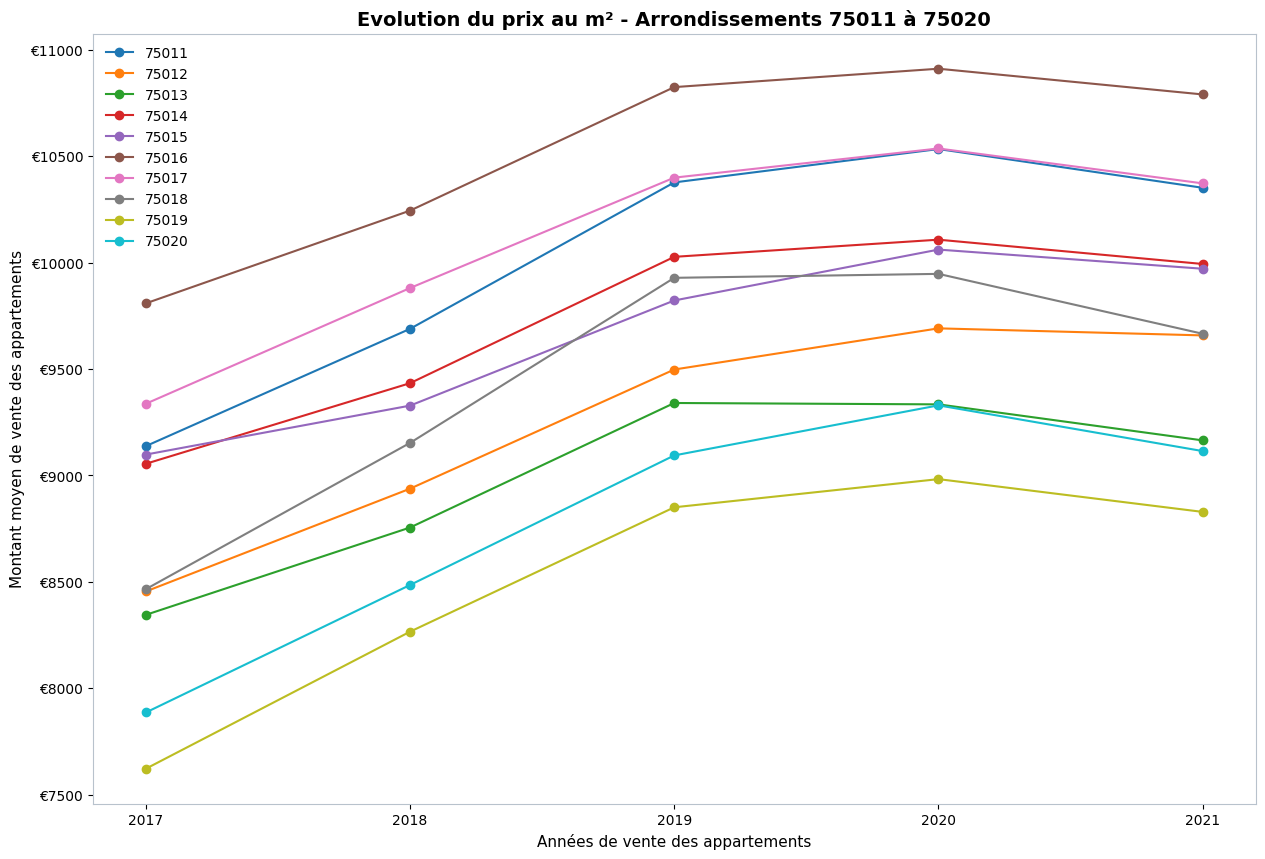

In [38]:
# J'affiche l'évolution du prix au m² pour les arrondissements 75011 à 75020
plt.figure(figsize=(15, 10))

for code_postal in range(75011, 75021):
    df_district_data = df_district_year_prices[
        df_district_year_prices["code_postal"] == code_postal
    ]

    plt.plot(
        df_district_data["annee"],
        df_district_data["prix_moyen_m2"],
        marker="o",
        label=str(code_postal)
    )

plt.xlabel("Années de vente des appartements")
plt.ylabel("Montant moyen de vente des appartements")
formatter = ticker.FormatStrFormatter("€%d")
plt.gca().yaxis.set_major_formatter(formatter)
plt.xticks(df_apartment_evolution["annee"])
plt.grid()
plt.title("Evolution du prix au m² - Arrondissements 75011 à 75020")
plt.legend(loc="upper left")
plt.show()


J'observe une hausse globale du prix moyen au mètre carré des appartements dans les arrondissements parisiens entre 2017 et 2020. Cette hausse semble généralisée, même si tous les arrondissements ne partent pas du même niveau de prix. Les arrondissements les plus chers restent globalement les plus chers sur toute la période, tandis que les moins chers conservent des niveaux plus bas. En 2021, la tendance semble ralentir, avec une stabilisation ou une légère baisse du prix moyen au mètre carré dans plusieurs arrondissements.

Le graphique montre une tendance générale, mais il est dense. Pour une lecture plus précise, il serait préférable de compléter avec un tableau trié par arrondissement ou de ne comparer que quelques arrondissements représentatifs.

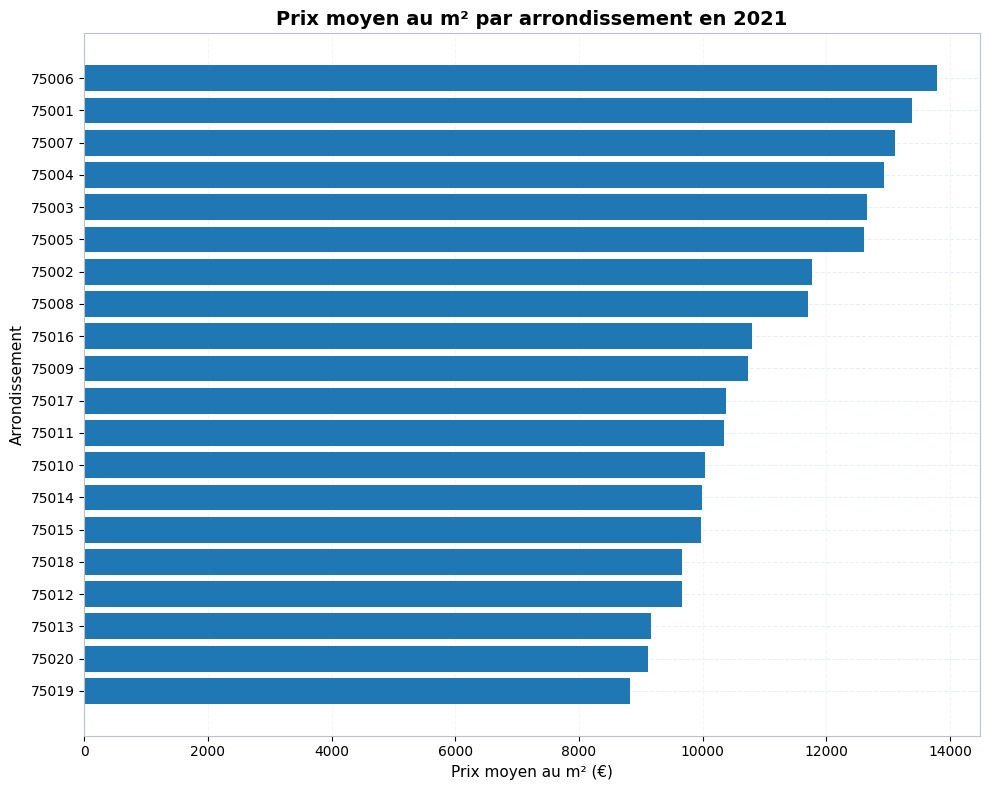

In [39]:
# Filtrer les prix de l'année 2021
df_prix_2021 = (
    df_district_year_prices[
        df_district_year_prices["annee"] == 2021
    ]
    .sort_values("prix_moyen_m2")
)

# Création du graphique
plt.figure(figsize=(10, 8))

plt.barh(
    df_prix_2021["code_postal"].astype(str),
    df_prix_2021["prix_moyen_m2"]
)

plt.title("Prix moyen au m² par arrondissement en 2021")
plt.xlabel("Prix moyen au m² (€)")
plt.ylabel("Arrondissement")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

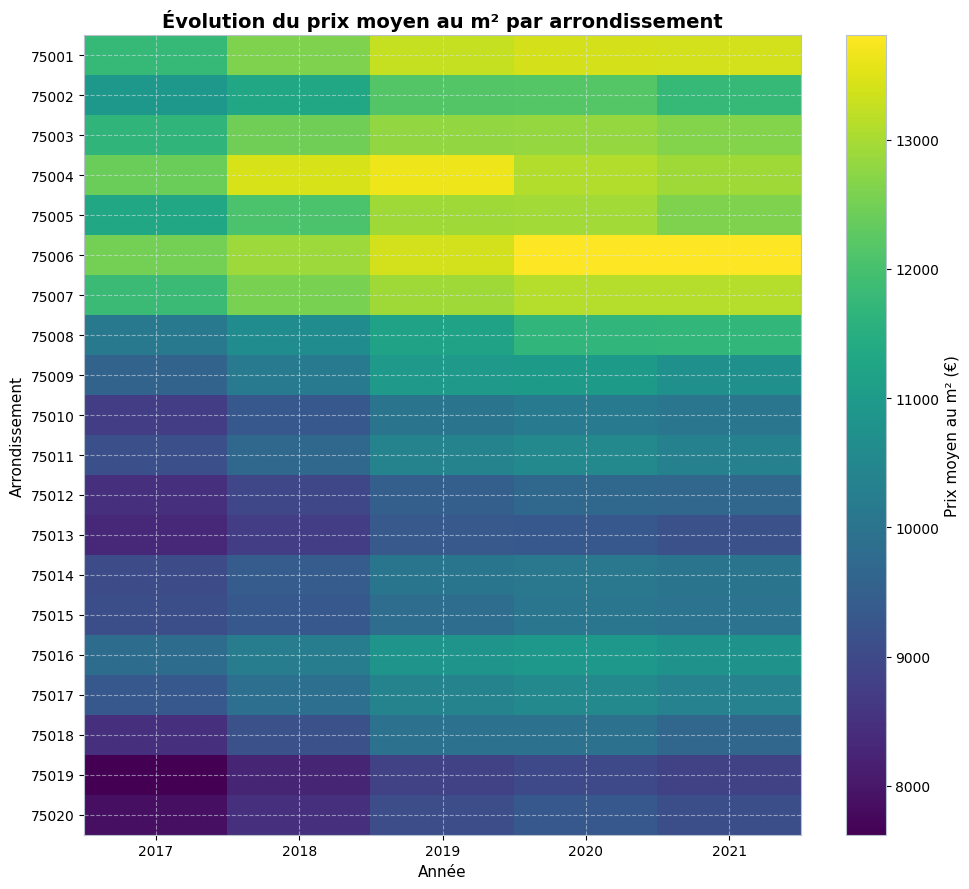

In [40]:
df_heatmap = (
    df_district_year_prices
    .pivot(
        index="code_postal",
        columns="annee",
        values="prix_moyen_m2"
    )
    .sort_index()
)

plt.figure(figsize=(10, 9))

plt.imshow(
    df_heatmap,
    aspect="auto"
)

plt.colorbar(label="Prix moyen au m² (€)")

plt.xticks(
    ticks=range(len(df_heatmap.columns)),
    labels=df_heatmap.columns
)

plt.yticks(
    ticks=range(len(df_heatmap.index)),
    labels=df_heatmap.index
)

plt.title("Évolution du prix moyen au m² par arrondissement")
plt.xlabel("Année")
plt.ylabel("Arrondissement")

plt.tight_layout()
plt.show()

### 7. Prix au metre carré par transaction dans un arrondissement

In [41]:
#Vérifions le nombre de transaction dans le 6ème car le prix semble élevé
nb_appartements_6 = (
    (df_history_clean["code_postal"] == 75006) &
    (df_history_clean["type_local"] == "Appartement")
).sum()

print("Le nombre de transactions pour les appartements du 6e arrondissement est :", nb_appartements_6)


Le nombre de transactions pour les appartements du 6e arrondissement est : 709


Je constate que le 6ᵉ arrondissement dispose de **709 transactions d'appartements** dans l'historique. Cet effectif est suffisamment important pour que son niveau de prix élevé ne repose pas sur quelques ventes isolées.

Affichons l'historique des transactions pour visualiser la dispersion des données :

In [42]:
df_apartments_75006 = df_apartment_history[
    df_apartment_history["code_postal"] == 75006
].copy()

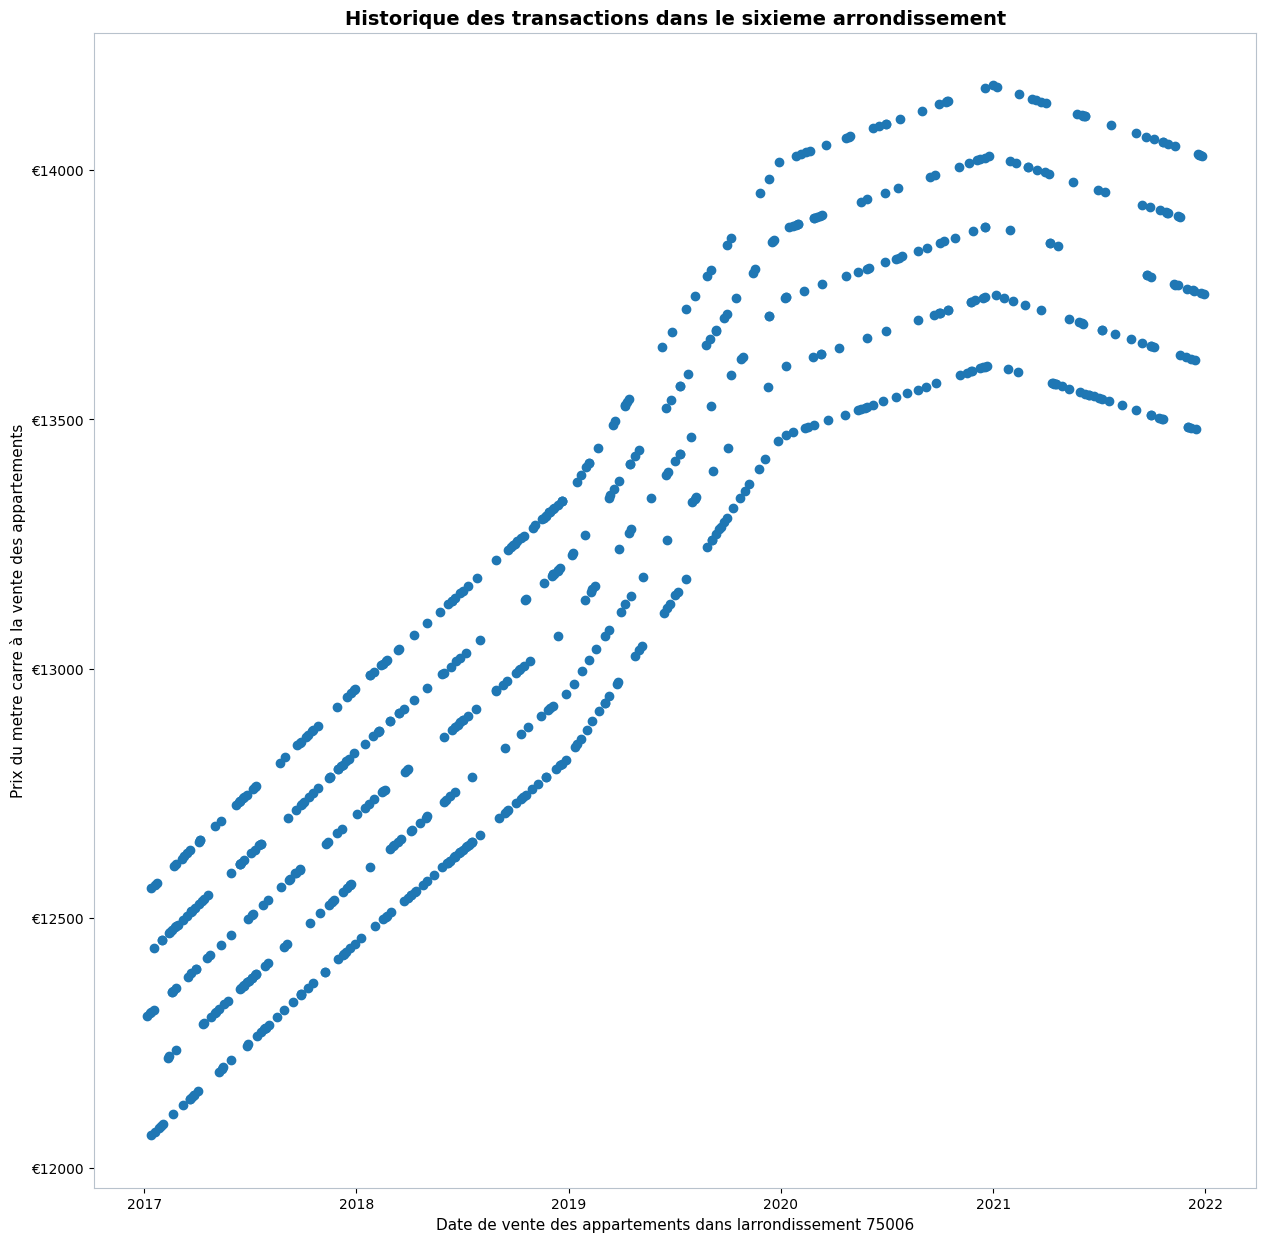

In [43]:
cp=75006
plt.figure(figsize=(15,15))
#Insérer ci-dessous le scatter plot
plt.scatter(df_apartments_75006["date_mutation"], df_apartments_75006["prix_au_m2"])
plt.xlabel('Date de vente des appartements dans larrondissement 75006')
plt.ylabel('Prix du metre carre à la vente des appartements')
formatter = ticker.FormatStrFormatter('€%d')
plt.gca().yaxis.set_major_formatter(formatter)

plt.grid(which='both')
plt.title('Historique des transactions dans le sixieme arrondissement')
plt.show()

J’observe une progression nette du prix au mètre carré au cours du temps, malgré une dispersion des transactions autour de la tendance générale. Les prix les plus récents se situent globalement à un niveau supérieur aux prix du début de période.

Pour mesurer statistiquement cette relation de manière cohérente avec la présentation, j’utilise le coefficient de corrélation de Pearson.

### 8. Vérification de la relation entre le prix au m² et la date dans le 6ème arrondissement avec Pearson

Pour cette analyse, j’utilise le coefficient de corrélation de Pearson. La date est transformée en nombre de jours afin de mesurer la relation linéaire entre le temps et le prix au mètre carré. L’objectif est de vérifier l’existence d’une association statistique, sans conclure automatiquement à un lien de causalité.

In [44]:
# Je calcule la corrélation de Pearson entre la date et le prix au m².
from scipy import stats

df_apartments_75006 = df_apartments_75006.dropna(
    subset=["date_mutation", "prix_au_m2"]
).copy()

date_numerique_75006 = (
    df_apartments_75006["date_mutation"]
    - df_apartments_75006["date_mutation"].min()
).dt.days

coefficient_pearson_date, p_value_pearson_date = stats.pearsonr(
    date_numerique_75006,
    df_apartments_75006["prix_au_m2"]
)

print(f"Coefficient de corrélation de Pearson : {coefficient_pearson_date:.3f}")
print(f"P-value : {p_value_pearson_date:.3e}")

if p_value_pearson_date < 0.05:
    print("La relation entre la date et le prix au m² est statistiquement significative.")
else:
    print("La relation observée n'est pas statistiquement significative au seuil de 5 %.")


Coefficient de corrélation de Pearson : 0.904
P-value : 7.108e-263
La relation entre la date et le prix au m² est statistiquement significative.


Le coefficient de Pearson est de **0,904** et la p-value est largement inférieure à 5 %. Je confirme donc une forte corrélation positive entre le temps et le prix au m² dans le 6ème arrondissement.

> **Interprétation :** le coefficient affiché mesure le sens et l’intensité de la relation linéaire entre le temps et le prix au m². Une p-value inférieure à 0,05 permet de rejeter l’hypothèse d’absence de corrélation statistiquement significative.

### 9. Vérification de la relation entre la surface réelle et le prix au m² avec Pearson

In [45]:
# Je vérifie la relation entre la surface réelle et le prix au m².
df_surface_prix_m2 = df_history_clean[
    ["surface_reelle", "prix_au_m2"]
].dropna().copy()

coefficient_pearson_surface, p_value_pearson_surface = stats.pearsonr(
    df_surface_prix_m2["surface_reelle"],
    df_surface_prix_m2["prix_au_m2"]
)

print(f"Coefficient de corrélation de Pearson : {coefficient_pearson_surface:.3f}")

if p_value_pearson_surface < 0.001:
    print("P-value : < 0.001")
else:
    print(f"P-value : {p_value_pearson_surface:.3f}")

if p_value_pearson_surface < 0.05:
    print("La relation entre la surface réelle et le prix au m² est statistiquement significative.")
else:
    print("La relation observée n'est pas statistiquement significative au seuil de 5 %.")


Coefficient de corrélation de Pearson : 0.103
P-value : < 0.001
La relation entre la surface réelle et le prix au m² est statistiquement significative.


Le coefficient de Pearson est de **0,103** avec une p-value inférieure à **0,001**. La relation est statistiquement significative, mais son intensité reste très faible. La surface explique surtout la valeur totale du bien, pas le niveau du prix au mètre carré.

> **Interprétation :** un coefficient positif très proche de 0 indique une relation faible entre la surface et le prix au m². La p-value valide l’existence statistique de la relation, mais pas son importance opérationnelle.

Regardons maintenant si le type de bien à une influence sur le prix au metre carré également.

### 10. Analyse des locaux industriels, commerciaux et assimilés 

In [46]:
# Je crée un dataset qui ne contient que les locaux commerciaux
df_commercial_history = df_history_clean[
    df_history_clean["type_local"] == "Local industriel. commercial ou assimilé"
].copy()

display(df_commercial_history.head())
print("Nombre de transactions de locaux commerciaux :", len(df_commercial_history))

,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,nom_commune,code_type_local,type_local,surface_reelle,prix_au_m2
18,2017-02-01,"3,113,277.30",65,RUE DE TURBIGO,75003,Paris 3e Arrondissement,4,Local industriel. commercial ou assimilé,250,"12,453.11"
29,2017-02-17,"1,164,375.26",17,RUE DU PONT AUX CHOUX,75003,Paris 3e Arrondissement,4,Local industriel. commercial ou assimilé,95,"12,256.58"
34,2017-02-20,"380,252.19",10,RUE CAFFARELLI,75003,Paris 3e Arrondissement,4,Local industriel. commercial ou assimilé,31,"12,266.20"
91,2017-03-09,"362,384.17",33,RUE DE RICHELIEU,75001,Paris 1er Arrondissement,4,Local industriel. commercial ou assimilé,29,"12,496.01"
109,2017-03-29,"315,907.23",130,RUE VIEILLE DU TEMPLE,75003,Paris 3e Arrondissement,4,Local industriel. commercial ou assimilé,25,"12,636.29"


Nombre de transactions de locaux commerciaux : 1842


In [47]:
#Préparons un dataframe en regroupant les prix au metre carré moyens des ventes par année
df_commercial_history["annee"] = df_commercial_history["date_mutation"].dt.year

df_commercial_evolution = (
    df_commercial_history
    .groupby("annee")
    .agg(
        prix_moyen_m2=("prix_au_m2", "mean"),
        surface_moyenne=("surface_reelle", "mean"),
        nb_transactions=("prix_au_m2", "count")
    )
    .reset_index()
)

display(df_commercial_evolution)

,annee,prix_moyen_m2,surface_moyenne,nb_transactions
0,2017,"10,944.06",90.20,348
1,2018,"11,569.50",88.10,351
2,2019,"11,960.13",82.83,432
3,2020,"11,966.47",85.63,336
4,2021,"12,006.49",92.83,375


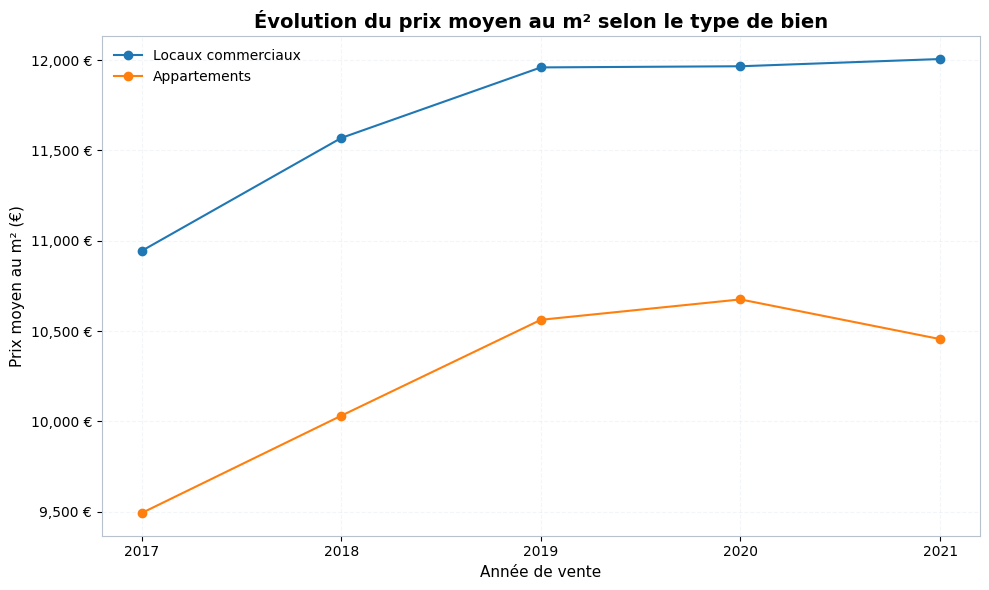

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_commercial_evolution["annee"],
    df_commercial_evolution["prix_moyen_m2"],
    marker="o",
    label="Locaux commerciaux"
)

plt.plot(
    df_apartment_evolution["annee"],
    df_apartment_evolution["prix_moyen_m2"],
    marker="o",
    label="Appartements"
)

plt.xlabel("Année de vente")
plt.ylabel("Prix moyen au m² (€)")
plt.title("Évolution du prix moyen au m² selon le type de bien")

plt.xticks([2017, 2018, 2019, 2020, 2021])

formatter = ticker.StrMethodFormatter("{x:,.0f} €")
plt.gca().yaxis.set_major_formatter(formatter)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Après ces analyses, Je peux conclure que les dimensions à utiliser pour prédire la **valeur foncière** sont : 
- la surface du bien immobilier,
- la date considérée,
- la localisation (`code_postal`),
- le type de bien.

# Milestone 2 - Entraînement de l'algorithme

Dans cette section, j’entraîne un algorithme pour prédire la valeur foncière d’un bien immobilier. Le modèle principal utilisé est la régression linéaire.

Je prépare les données en transformant les colonnes catégorielles du code postal et du type de local avec `pd.get_dummies`.

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

# Préparation des variables explicatives
df_model = df_history_clean[
    ["date_mutation", "surface_reelle", "code_postal", "type_local", "valeur_fonciere"]
].dropna().copy()

# Transformation de la date en nombre de jours depuis la première date de l'historique
date_reference = df_model["date_mutation"].min()
df_model["date_numerique"] = (
    df_model["date_mutation"] - date_reference
).dt.days

# One-hot encoding des variables catégorielles
X = pd.get_dummies(
    df_model[["date_numerique", "surface_reelle", "code_postal", "type_local"]],
    columns=["code_postal", "type_local"],
    drop_first=False,
    dtype=int
)

y = df_model["valeur_fonciere"]

display(X.head())
print("Dimensions de X :", X.shape)

,date_numerique,surface_reelle,code_postal_75001,code_postal_75002,code_postal_75003,code_postal_75004,code_postal_75005,code_postal_75006,code_postal_75007,code_postal_75008,...,code_postal_75013,code_postal_75014,code_postal_75015,code_postal_75016,code_postal_75017,code_postal_75018,code_postal_75019,code_postal_75020,type_local_Appartement,type_local_Local industriel. commercial ou assimilé
0,1,50,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,10,163,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,8,66,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
3,8,22,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,11,15,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


Dimensions de X : (26180, 24)


J’utilise `train_test_split` pour conserver 33 % des données en test. J’entraîne le modèle sur le reste des données, puis je mesure l’erreur moyenne en pourcentage de la valeur foncière.

In [50]:
# Je sépare le jeu de données entre échantillons d'apprentissage et de test
# La valeur y à trouver est la valeur foncière
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42
)

print("Taille du jeu d'entraînement :", X_train.shape)
print("Taille du jeu de test :", X_test.shape)


Taille du jeu d'entraînement : (17540, 24)
Taille du jeu de test : (8640, 24)


In [51]:
# Conversion des données en str
# Les colonnes catégorielles ont déjà été converties en indicatrices numériques
# par get_dummies. Je vérifie que toutes les variables sont exploitables.
X_train = X_train.astype(float)
X_test = X_test.astype(float)
y_train = y_train.astype(float)
y_test = y_test.astype(float)

display(X_train.dtypes.value_counts())


float64    24
Name: count, dtype: int64

In [52]:
from sklearn.linear_model import LinearRegression

# J'entraîne une première régression linéaire pour mesurer la performance sur le jeu de test.
model_linear = LinearRegression()
model_linear.fit(X_train, y_train)

y_pred = model_linear.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
r2 = r2_score(y_test, y_pred)

print(f"Erreur absolue moyenne : {mae:,.2f} €")
print(f"Erreur moyenne en pourcentage : {mape:.2f} %")
print(f"Coefficient de détermination R² : {r2:.3f}")

# J'entraîne ensuite le modèle final sur 100 % de l'historique pour valoriser le portefeuille.
model_linear_final = LinearRegression()
model_linear_final.fit(X.astype(float), y.astype(float))

print(f"Modèle final entraîné sur l'historique complet : {len(X):,} transactions")


Erreur absolue moyenne : 32,821.64 €
Erreur moyenne en pourcentage : 9.05 %
Coefficient de détermination R² : 0.982
Modèle final entraîné sur l'historique complet : 26,180 transactions


Je retiens une erreur moyenne de **9,05 %** sur le jeu de test.

Mes conclusions sur ce résultat et les pistes d’amélioration :
- Le modèle présente une bonne performance globale, avec un MAPE de **9,05 %**.
- L’erreur absolue moyenne est de **32 821,64 €**.
- Le coefficient de détermination **R² = 0,982** indique que le modèle explique environ **98,2 %** de la variabilité des valeurs foncières.
- Pour aller plus loin, je pourrais tester d’autres modèles, ajouter davantage de variables explicatives et utiliser une validation croisée pour vérifier la stabilité des performances.

# Milestone 3 - Prédiction définitive pour le client 

J’ai récupéré le fichier contenant le portefeuille des actifs de la société. Je l’importe, puis je réalise la prédiction au **31 décembre 2022** afin d’identifier le segment qui présente la valorisation la plus élevée.

Je conserve la surface réelle pour les calculs, et non la surface Carrez.

In [53]:
# J'importe les données dans un dataframe
# Les données du portefeuille ont déjà été importées au début du notebook.
df_wallet_prediction = df_wallet_clean.copy()

display(df_wallet_prediction.head())
print("Nombre de biens à valoriser :", len(df_wallet_prediction))



,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,surface_carrez,code_type_local,type_local,surface_reelle_bati,nombre_pieces_principales,longitude,latitude
0,127,RUE SAINT-DENIS,75001,75101,Paris 1er Arrondissement,16.41,2,Appartement,25,1,2.35,48.86
1,62,RUE NOTRE-DAME DE NAZARETH,75003,75103,Paris 3e Arrondissement,20.47,2,Appartement,22,1,2.36,48.87
2,62,RUE DE TURENNE,75003,75103,Paris 3e Arrondissement,64.48,2,Appartement,65,3,2.36,48.86
3,32,AV GEORGE V,75008,75108,Paris 8e Arrondissement,63.29,2,Appartement,74,2,2.30,48.87
4,152,BD HAUSSMANN,75008,75108,Paris 8e Arrondissement,20.58,2,Appartement,22,1,2.31,48.88


Nombre de biens à valoriser : 273


J’ai la liste des biens immobiliers de l’entreprise. Pour réaliser la prédiction, je mets ce fichier au même format que le jeu utilisé lors de l’entraînement du modèle.

In [54]:
#je réutilise les mêmes fonctions pour faire le one hot encoding des variables catégorielles

# J'importe la librairie datetime pour pouvoir créer une colonne timestamp avec la date du 31 décembre 2022 pour la prédiction
import datetime as dt
# Harmonisation du nom de la surface avec celui utilisé lors de l'entraînement
df_wallet_prediction["surface_reelle"] = df_wallet_prediction["surface_reelle_bati"]

# Tous les biens sont valorisés au 31 décembre 2022
date_prediction = pd.Timestamp("2022-12-31")
df_wallet_prediction["date_numerique"] = (
    date_prediction - date_reference
).days

# Même encodage que pour le jeu d'entraînement
X_wallet = pd.get_dummies(
    df_wallet_prediction[
        ["date_numerique", "surface_reelle", "code_postal", "type_local"]
    ],
    columns=["code_postal", "type_local"],
    drop_first=False,
    dtype=int
)

# Alignement strict sur les colonnes utilisées par le modèle
X_wallet = X_wallet.reindex(columns=X.columns, fill_value=0)

display(X_wallet.head())
print("Dimensions des données de prédiction :", X_wallet.shape)



,date_numerique,surface_reelle,code_postal_75001,code_postal_75002,code_postal_75003,code_postal_75004,code_postal_75005,code_postal_75006,code_postal_75007,code_postal_75008,...,code_postal_75013,code_postal_75014,code_postal_75015,code_postal_75016,code_postal_75017,code_postal_75018,code_postal_75019,code_postal_75020,type_local_Appartement,type_local_Local industriel. commercial ou assimilé
0,2189,25,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2189,22,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,2189,65,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,2189,74,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
4,2189,22,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0


Dimensions des données de prédiction : (273, 24)


Le type de local est conservé dans une seule colonne dans le dataframe métier. Pour être utilisé par le modèle, il est temporairement transformé en colonnes indicatrices par `pd.get_dummies`, puis les colonnes du portefeuille sont alignées sur celles utilisées pendant l'entraînement.

In [55]:
#Conversion du dataframe en str
X_wallet = X_wallet.astype(float)
display(X_wallet.dtypes.value_counts())

float64    24
Name: count, dtype: int64

Le dataframe est prêt pour la prédiction finale.

In [56]:
# Je calcule les valeurs prédites avec le modèle final entraîné sur 100 % de l'historique.
df_wallet_prediction["valeur_fonciere_predite"] = model_linear_final.predict(X_wallet)

display(
    df_wallet_prediction[
        [
            "adresse_numero",
            "adresse_nom_voie",
            "code_postal",
            "type_local",
            "surface_reelle_bati",
            "valeur_fonciere_predite"
        ]
    ].head(10)
)


,adresse_numero,adresse_nom_voie,code_postal,type_local,surface_reelle_bati,valeur_fonciere_predite
0,127,RUE SAINT-DENIS,75001,Appartement,25,"435,840.20"
1,62,RUE NOTRE-DAME DE NAZARETH,75003,Appartement,22,"369,601.44"
2,62,RUE DE TURENNE,75003,Appartement,65,"822,767.98"
3,32,AV GEORGE V,75008,Appartement,74,"876,591.88"
4,152,BD HAUSSMANN,75008,Appartement,22,"328,576.53"
5,152,BD HAUSSMANN,75008,Appartement,35,"465,580.37"
6,52,RUE DES GRAVILLIERS,75003,Appartement,24,"390,678.95"
7,208,RUE SAINT MAUR,75010,Appartement,60,"642,304.57"
8,142,RUE DE COURCELLES,75017,Appartement,11,"145,083.33"
9,52,RUE LAMARCK,75018,Appartement,13,"145,090.72"


Je compare maintenant la valorisation prédite pour les deux segments.

In [57]:
valorisation_par_segment = (
    df_wallet_prediction
    .groupby("type_local", as_index=False)
    .agg(
        nombre_de_biens=("valeur_fonciere_predite", "count"),
        valorisation_predite=("valeur_fonciere_predite", "sum")
    )
)

valorisation_par_segment["valorisation_millions_euros"] = (
    valorisation_par_segment["valorisation_predite"] / 1_000_000
)

display(valorisation_par_segment)


,type_local,nombre_de_biens,valorisation_predite,valorisation_millions_euros
0,Appartement,154,"71,221,764.00",71.22
1,Local industriel. commercial ou assimilé,119,"97,532,690.19",97.53


In [58]:
print("Valorisation du segment particuliers, en millions d'euros :")
valorisation_particuliers = df_wallet_prediction.loc[
    df_wallet_prediction["type_local"] == "Appartement",
    "valeur_fonciere_predite"
].sum() / 1_000_000

print(f"{valorisation_particuliers:,.2f} M€")


Valorisation du segment particuliers, en millions d'euros :
71.22 M€


In [59]:
print("Valorisation du segment corporate, en millions d'euros :")
valorisation_corporate = df_wallet_prediction.loc[
    df_wallet_prediction["type_local"] == "Local industriel. commercial ou assimilé",
    "valeur_fonciere_predite"
].sum() / 1_000_000

print(f"{valorisation_corporate:,.2f} M€")


Valorisation du segment corporate, en millions d'euros :
97.53 M€


Mes conclusions sur le segment avec la plus grande valorisation et sur les limites de cette estimation :
- Le segment corporate présente la valorisation totale prédite la plus élevée avec **97,53 M€**.
- Le segment des appartements représente **71,22 M€**.
- La valorisation totale du portefeuille atteint **168,75 M€** après suppression des doublons.
- Cette estimation reste une projection fondée sur les tendances historiques de 2017 à 2021. Elle ne prend pas directement en compte les changements de marché après 2021, l’état précis des biens, leur étage, leur qualité, leur occupation ou d’autres caractéristiques susceptibles d’influencer leur valeur.

# Milestone 4 - Classification des données issues de l'échantillon à classer

Dans cette partie, je labellise automatiquement les biens immobiliers comme étant :
- soit des appartements ;
- soit des locaux industriels, commerciaux ou assimilés.

J’utilise l’algorithme KMeans sur le jeu de données partagé par l’entreprise.

Pour que l’algorithme fonctionne, je prépare les données en supprimant les dimensions inutiles et en conservant le facteur discriminant principal entre les appartements et les locaux commerciaux : le prix au mètre carré.

In [60]:
df_classification = df_sample.copy()

colonnes_requises = ["valeur_fonciere", "surface_reelle"]

if not set(colonnes_requises).issubset(df_classification.columns):
    colonnes_manquantes = set(colonnes_requises) - set(df_classification.columns)
    raise ValueError(f"Colonnes manquantes : {colonnes_manquantes}")

display(df_classification.head())
print("Nombre de biens à classer :", len(df_classification))

,valeur_fonciere,code_postal,nom_commune,surface_reelle
0,"868,687.08",75019,Paris 19e Arrondissement,88
1,"452,050.76",75019,Paris 19e Arrondissement,45
2,"193,088.65",75019,Paris 19e Arrondissement,21
3,"303,012.55",75019,Paris 19e Arrondissement,32
4,"149,272.20",75019,Paris 19e Arrondissement,20


Nombre de biens à classer : 40


J’applique les transformations nécessaires. Je calcule d’abord le prix au mètre carré en divisant la valeur foncière par la surface réelle. Je conserve ensuite cette variable pour le regroupement KMeans.

Tous les biens de l’échantillon se trouvent dans le même arrondissement. Le prix au m² devient donc la variable la plus utile pour séparer les deux groupes.

In [61]:
# Préparation de la variable discriminante : le prix au mètre carré
df_classification = df_classification.dropna(
    subset=["valeur_fonciere", "surface_reelle"]
).copy()

df_classification = df_classification[
    df_classification["surface_reelle"] > 0
].copy()

df_classification["prix_au_m2"] = (
    df_classification["valeur_fonciere"]
    / df_classification["surface_reelle"]
)

# KMeans recevra uniquement la variable numérique utile au regroupement
X_classification = df_classification[["prix_au_m2"]].copy()

display(X_classification.describe())

,prix_au_m2
count,40.00
mean,"8,607.85"
std,"1,229.15"
min,"7,207.22"
25%,"7,386.68"
50%,"8,430.38"
75%,"9,829.34"
max,"10,113.20"


In [62]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Deux groupes sont recherchés : appartements et locaux commerciaux
kmeans = KMeans(
    n_clusters=2,
    random_state=42, ## à tester, adapter 
    n_init=10
)

df_classification["cluster"] = kmeans.fit_predict(X_classification)
centres_clusters = kmeans.cluster_centers_.flatten()
annee_reference_classification = df_history_clean["date_mutation"].dt.year.max()
codes_reference_classification = df_classification["code_postal"].dropna().unique()

reference_types = (
    df_history_clean[
        (df_history_clean["date_mutation"].dt.year == annee_reference_classification)
        & (df_history_clean["code_postal"].isin(codes_reference_classification))
    ]
    .groupby("type_local")["prix_au_m2"]
    .mean()
    .sort_values()
)

# Solution de repli si les deux types ne sont pas présents dans la zone comparable.
if len(reference_types) < 2:
    reference_types = (
        df_history_clean[
            df_history_clean["date_mutation"].dt.year == annee_reference_classification
        ]
        .groupby("type_local")["prix_au_m2"]
        .mean()
        .sort_values()
    )

if len(reference_types) != 2:
    raise ValueError(
        "Impossible d'attribuer les deux clusters : les deux types de locaux "
        "ne sont pas disponibles dans l'historique de référence."
    )

cluster_prix_bas = int(np.argmin(centres_clusters))
cluster_prix_haut = int(np.argmax(centres_clusters))
type_prix_bas = reference_types.index[0]
type_prix_haut = reference_types.index[-1]

correspondance_clusters = {
    cluster_prix_bas: type_prix_bas,
    cluster_prix_haut: type_prix_haut
}

df_classification["type_local_predit"] = (
    df_classification["cluster"].map(correspondance_clusters)
)

print("Prix moyens historiques de référence :")
display(reference_types.to_frame("prix_moyen_m2"))


Prix moyens historiques de référence :


,prix_moyen_m2
type_local,
Appartement,"8,828.59"
Local industriel. commercial ou assimilé,"9,737.62"


In [63]:
# vérification des résultats de la classification
score_silhouette = silhouette_score(
    X_classification,
    df_classification["cluster"]
)

resume_clusters = (
    df_classification
    .groupby(["cluster", "type_local_predit"], as_index=False)
    .agg(
        nombre_de_biens=("prix_au_m2", "size"),
        prix_moyen_m2=("prix_au_m2", "mean"),
        prix_median_m2=("prix_au_m2", "median")
    )
    .sort_values("prix_moyen_m2")
)

print("Centres des clusters :")
for numero_cluster, centre in enumerate(centres_clusters):
    print(
        f"- Cluster {numero_cluster} : {centre:,.2f} €/m² "
        f"→ {correspondance_clusters[numero_cluster]}"
    )

print(f"Score de silhouette : {score_silhouette:.3f}")
display(resume_clusters)

Centres des clusters :
- Cluster 0 : 7,408.78 €/m² → Appartement
- Cluster 1 : 9,806.92 €/m² → Local industriel. commercial ou assimilé
Score de silhouette : 0.909


,cluster,type_local_predit,nombre_de_biens,prix_moyen_m2,prix_median_m2
0,0,Appartement,20,"7,408.78","7,374.09"
1,1,Local industriel. commercial ou assimilé,20,"9,806.92","9,842.72"


,valeur_fonciere,code_postal,nom_commune,surface_reelle,prix_au_m2,cluster,type_local_predit
21,"252,252.62",75019,Paris 19e Arrondissement,35,"7,207.22",0,Appartement
12,"188,199.00",75019,Paris 19e Arrondissement,26,"7,238.42",0,Appartement
35,"456,118.94",75019,Paris 19e Arrondissement,63,"7,239.98",0,Appartement
34,"160,472.45",75019,Paris 19e Arrondissement,22,"7,294.20",0,Appartement
19,"269,985.32",75019,Paris 19e Arrondissement,37,"7,296.90",0,Appartement
25,"255,738.36",75019,Paris 19e Arrondissement,35,"7,306.81",0,Appartement
15,"299,837.69",75019,Paris 19e Arrondissement,41,"7,313.11",0,Appartement
20,"256,289.97",75019,Paris 19e Arrondissement,35,"7,322.57",0,Appartement
14,"323,115.73",75019,Paris 19e Arrondissement,44,"7,343.54",0,Appartement
7,"462,981.80",75019,Paris 19e Arrondissement,63,"7,348.92",0,Appartement


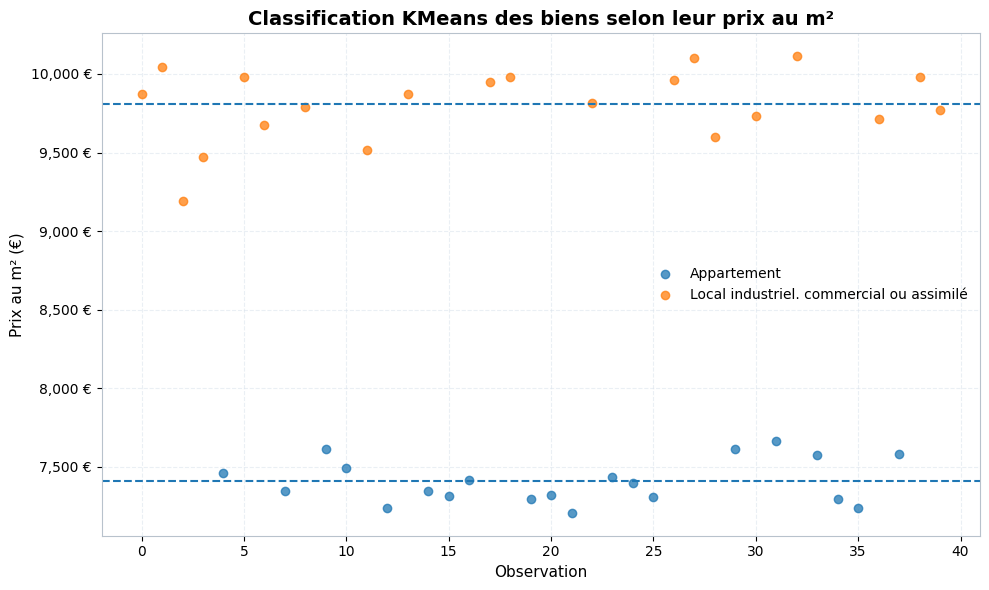

In [64]:
# affichage des résultats détaillés
resultats_classification = df_classification[
    [
        "valeur_fonciere",
        "code_postal",
        "nom_commune",
        "surface_reelle",
        "prix_au_m2",
        "cluster",
        "type_local_predit"
    ]
].sort_values("prix_au_m2")

display(resultats_classification)

# Visualisation des deux groupes sur le prix au m²
plt.figure(figsize=(10, 6))

for type_local, groupe in df_classification.groupby("type_local_predit"):
    plt.scatter(
        groupe.index,
        groupe["prix_au_m2"],
        alpha=0.75,
        label=type_local
    )

for centre in centres_clusters:
    plt.axhline(
        centre,
        linestyle="--",
        linewidth=1.5
    )

plt.title("Classification KMeans des biens selon leur prix au m²")
plt.xlabel("Observation")
plt.ylabel("Prix au m² (€)")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x:,.0f} €")
)
plt.legend()
plt.tight_layout()
plt.show()

In [65]:
# Je vérifie les prédictions KMeans sur les biens retrouvés dans l'historique.
cles_controle_classification = [
    "valeur_fonciere",
    "code_postal",
    "nom_commune",
    "surface_reelle"
]

df_controle_classification = df_classification.merge(
    df_history_clean[cles_controle_classification + ["type_local"]],
    on=cles_controle_classification,
    how="inner"
)

df_controle_classification["classification_correcte"] = (
    df_controle_classification["type_local_predit"]
    == df_controle_classification["type_local"]
)

nombre_biens_verifiables = len(df_controle_classification)
nombre_concordances = int(df_controle_classification["classification_correcte"].sum())
taux_concordance = (
    nombre_concordances / nombre_biens_verifiables * 100
    if nombre_biens_verifiables > 0
    else np.nan
)

print("Biens de l'échantillon retrouvés dans l'historique :", nombre_biens_verifiables)
print("Classifications concordantes :", nombre_concordances)
print(f"Taux de concordance sur les biens vérifiables : {taux_concordance:.1f} %")

display(
    df_controle_classification[
        [
            "valeur_fonciere",
            "code_postal",
            "surface_reelle",
            "prix_au_m2",
            "type_local_predit",
            "type_local",
            "classification_correcte"
        ]
    ].sort_values("prix_au_m2")
)


Biens de l'échantillon retrouvés dans l'historique : 16
Classifications concordantes : 16
Taux de concordance sur les biens vérifiables : 100.0 %


,valeur_fonciere,code_postal,surface_reelle,prix_au_m2,type_local_predit,type_local,classification_correcte
13,"160,472.45",75019,22,"7,294.20",Appartement,Appartement,True
10,"255,738.36",75019,35,"7,306.81",Appartement,Appartement,True
6,"299,837.69",75019,41,"7,313.11",Appartement,Appartement,True
8,"256,289.97",75019,35,"7,322.57",Appartement,Appartement,True
5,"323,115.73",75019,44,"7,343.54",Appartement,Appartement,True
9,"177,582.38",75019,24,"7,399.27",Appartement,Appartement,True
3,"374,523.45",75019,50,"7,490.47",Appartement,Appartement,True
12,"113,655.67",75019,15,"7,577.04",Appartement,Appartement,True
2,"403,670.31",75019,53,"7,616.42",Appartement,Appartement,True
14,"194,310.63",75019,20,"9,715.53",Local industriel. commercial ou assimilé,Local industriel. commercial ou assimilé,True


# Milestone 5 - Analyse et présentation des résultats

## Synthèse des analyses réalisées

### Évolution du marché immobilier parisien

L’historique immobilier parisien de 2017 à 2021 met en évidence plusieurs facteurs importants dans la détermination de la valeur d’un bien : la surface, la localisation, la date de transaction et le type de local.

Le prix moyen au mètre carré des appartements parisiens augmente globalement sur la période étudiée. Il passe d’environ **9 492 €/m² en 2017** à **10 456 €/m² en 2021**. La progression atteint un pic en 2020, avec environ **10 675 €/m²**, puis un léger repli apparaît en 2021.

### Différences entre les arrondissements

Les prix au mètre carré varient fortement selon les arrondissements. Les arrondissements les plus chers au début de la période restent globalement les plus chers jusqu’en 2021. La localisation reste donc une variable essentielle pour expliquer la valeur foncière d’un bien.

Dans le 1er arrondissement, le prix moyen passe notamment d’environ **11 763 €/m² en 2017** à **13 380 €/m² en 2021**.

### Corrélations de Pearson

Dans le 6ème arrondissement, le coefficient de Pearson entre la date de vente et le prix au mètre carré est de **0,904**, avec une p-value très inférieure à 5 %. Je retiens donc une forte relation positive entre le temps et le prix au mètre carré dans cet arrondissement.

Entre la surface réelle et le prix au mètre carré, le coefficient de Pearson est de **0,103**. La relation est statistiquement significative, mais très faible. La surface explique surtout la valeur totale du bien, pas le niveau du prix au mètre carré.

### Comparaison selon le type de local

Les locaux industriels, commerciaux ou assimilés représentent **1 842 transactions** dans l’historique.

Leur prix moyen au mètre carré passe d’environ **10 944 €/m² en 2017** à **12 006 €/m² en 2021**. Leur surface moyenne est également plus élevée que celle des appartements, puisqu’elle se situe généralement entre **83 et 93 m²**.

La comparaison entre appartements et locaux commerciaux confirme que le type de bien influence le prix au mètre carré et doit être intégré au modèle de prédiction.

## Performance du modèle de prédiction

J’ai entraîné une régression linéaire à partir des variables suivantes :

- la surface réelle ;
- la date de mutation ;
- le code postal ;
- le type de local.

Le modèle obtient les résultats suivants sur le jeu de test :

- **erreur absolue moyenne : 32 821,64 €** ;
- **erreur moyenne en pourcentage : 9,05 %** ;
- **coefficient de détermination R² : 0,982**.

J’utilise le train/test split uniquement pour évaluer la performance. Pour la valorisation finale, j’entraîne ensuite une seconde régression linéaire sur **100 % des 26 180 transactions**.

## Valorisation du portefeuille

Le modèle final est appliqué au portefeuille immobilier au **31 décembre 2022**. Après suppression des doublons, **273 biens** sont valorisés.

La valorisation prédite est répartie de la manière suivante :

- **154 appartements**, pour une valeur totale estimée à **71,22 M€** ;
- **119 locaux industriels, commerciaux ou assimilés**, pour une valeur totale estimée à **97,53 M€**.

La valorisation totale prédite du portefeuille est donc d’environ **168,75 M€**.

Le segment corporate présente la valorisation totale la plus élevée. Cette différence s’explique notamment par des surfaces moyennes plus importantes et par la valeur individuelle de certains biens.

## Classification de l’échantillon

J’utilise KMeans pour répartir automatiquement les **40 biens** de l’échantillon en deux groupes à partir du prix au mètre carré.

Les deux groupes obtenus sont les suivants :

- un groupe de **20 biens**, avec un centre d’environ **7 409 €/m²**, interprété comme **appartements** ;
- un groupe de **20 biens**, avec un centre d’environ **9 807 €/m²**, interprété comme **locaux industriels, commerciaux ou assimilés**.

Le score de silhouette est de **0,909**. Les deux groupes sont donc bien séparés selon la variable utilisée.

J’ai aussi rapproché l’échantillon avec l’historique. **16 biens** sont retrouvés exactement dans les transactions historiques, et les **16 classifications sont concordantes** avec le type réel retrouvé.

## Conclusion générale

Je retiens une valorisation cohérente du portefeuille et une classification KMeans exploitable pour l’échantillon fourni. Les résultats restent à utiliser avec prudence, car le modèle repose sur des données historiques limitées à la période 2017-2021 et certaines caractéristiques importantes des biens ne sont pas disponibles.

Pour aller plus loin, je pourrais intégrer des données immobilières plus récentes, ajouter des variables comme l’état du bien ou la proximité des transports, puis comparer la régression linéaire à des modèles plus flexibles.

# Visualisations complémentaires

Les graphiques ci-dessous complètent l'analyse existante sans modifier les traitements précédents.


## Surface réelle vs valeur foncière


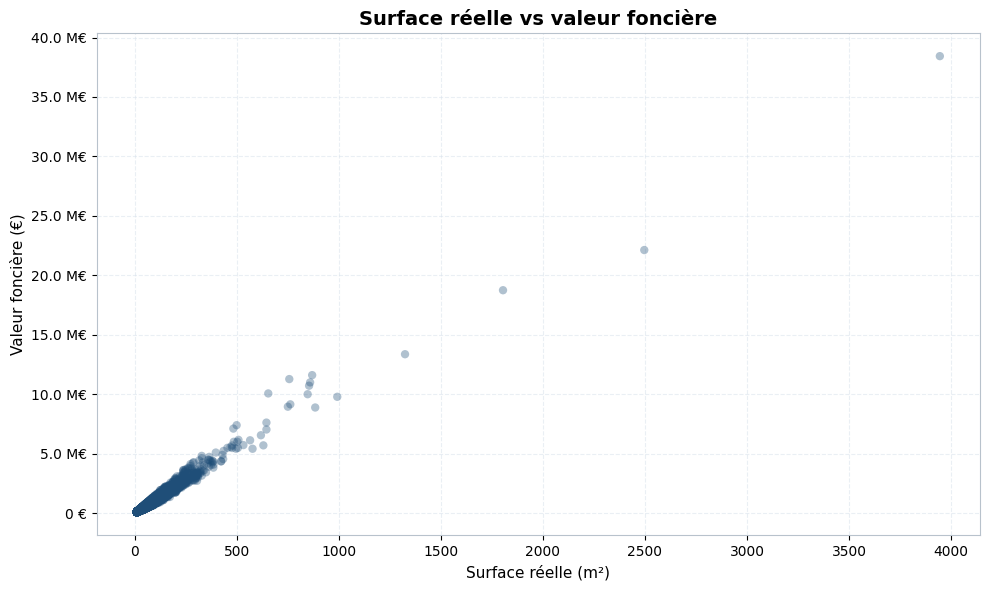

In [66]:
# Relation entre la surface réelle et la valeur foncière
df_surface_valeur_graph = df_history_clean[
    ["surface_reelle", "valeur_fonciere"]
].dropna()

plt.figure(figsize=(10, 6))
plt.scatter(
    df_surface_valeur_graph["surface_reelle"],
    df_surface_valeur_graph["valeur_fonciere"],
    alpha=0.35,
    color=COULEUR_PRINCIPALE,
    edgecolors="none"
)
plt.title("Surface réelle vs valeur foncière")
plt.xlabel("Surface réelle (m²)")
plt.ylabel("Valeur foncière (€)")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f} M€" if abs(x) >= 1_000_000 else f"{x:,.0f} €")
)
plt.tight_layout()
plt.show()


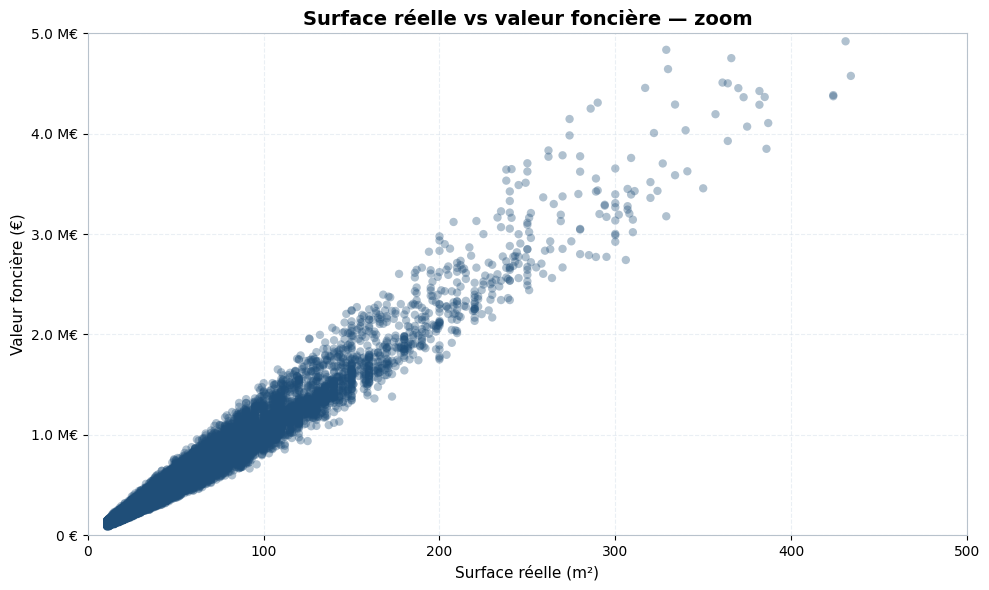

In [67]:
# Zoom sur la zone principale : petites et moyennes surfaces

plt.figure(figsize=(10, 6))

plt.scatter(
    df_surface_valeur_graph["surface_reelle"],
    df_surface_valeur_graph["valeur_fonciere"],
    alpha=0.35,
    color=COULEUR_PRINCIPALE,
    edgecolors="none"
)

plt.title("Surface réelle vs valeur foncière — zoom")
plt.xlabel("Surface réelle (m²)")
plt.ylabel("Valeur foncière (€)")

# Limites d'affichage pour créer le zoom
plt.xlim(0, 500)
plt.ylim(0, 5_000_000)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.tight_layout()
plt.show()

### Zoom sur les biens de petites et moyennes surfaces

Le graphique global met en évidence quelques biens présentant des surfaces et des valeurs foncières très élevées. Ces valeurs extrêmes réduisent la lisibilité de la majorité des observations.

Un second graphique est donc présenté avec un zoom sur les biens dont la surface réelle est inférieure à 500 m² et la valeur foncière inférieure à 5 millions d’euros. Les données ne sont pas supprimées : seules les limites d’affichage du graphique sont modifiées.

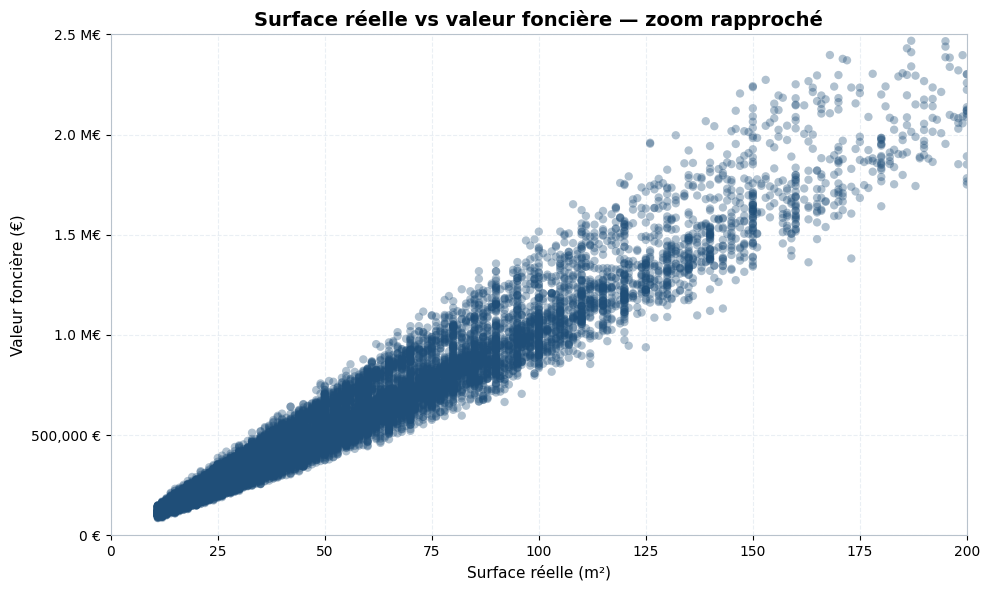

In [68]:
# Zoom plus rapproché

plt.figure(figsize=(10, 6))

plt.scatter(
    df_surface_valeur_graph["surface_reelle"],
    df_surface_valeur_graph["valeur_fonciere"],
    alpha=0.35,
    color=COULEUR_PRINCIPALE,
    edgecolors="none"
)

plt.title("Surface réelle vs valeur foncière — zoom rapproché")
plt.xlabel("Surface réelle (m²)")
plt.ylabel("Valeur foncière (€)")

# Zoom plus précis
plt.xlim(0, 200)
plt.ylim(0, 2_500_000)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.tight_layout()
plt.show()

## Prix au m² par type de local


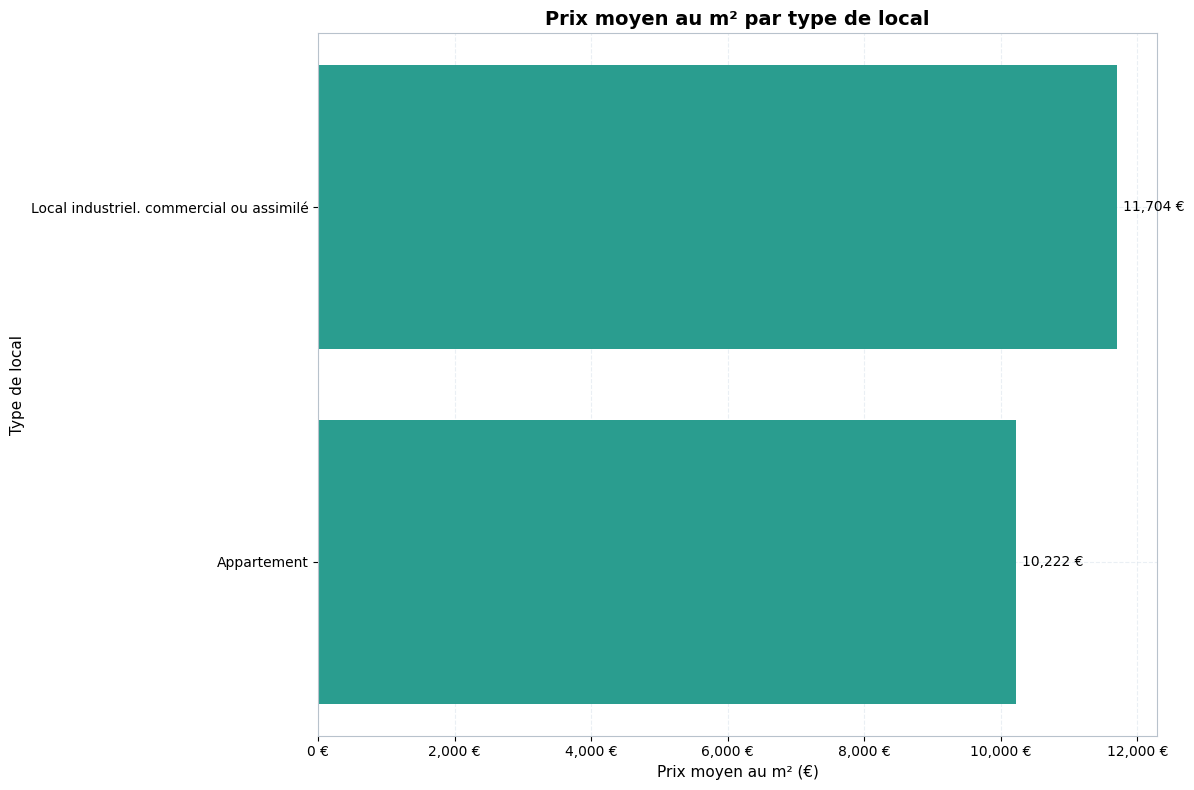

In [69]:
df_prix_type_local = (
    df_history_clean
    .dropna(subset=["type_local", "prix_au_m2"])
    .groupby("type_local", as_index=False)
    .agg(prix_moyen_m2=("prix_au_m2", "mean"))
    .sort_values("prix_moyen_m2")
)

plt.figure(figsize=(12, 8))
bars = plt.barh(
    df_prix_type_local["type_local"],
    df_prix_type_local["prix_moyen_m2"],
    color=COULEUR_SECONDAIRE
)
plt.title("Prix moyen au m² par type de local")
plt.xlabel("Prix moyen au m² (€)")
plt.ylabel("Type de local")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x:,.0f} €")
)
plt.bar_label(
    bars,
    labels=[f"{v:,.0f} €" for v in df_prix_type_local["prix_moyen_m2"]],
    padding=4
)
plt.tight_layout()
plt.show()


## Prix médian au m² par arrondissement


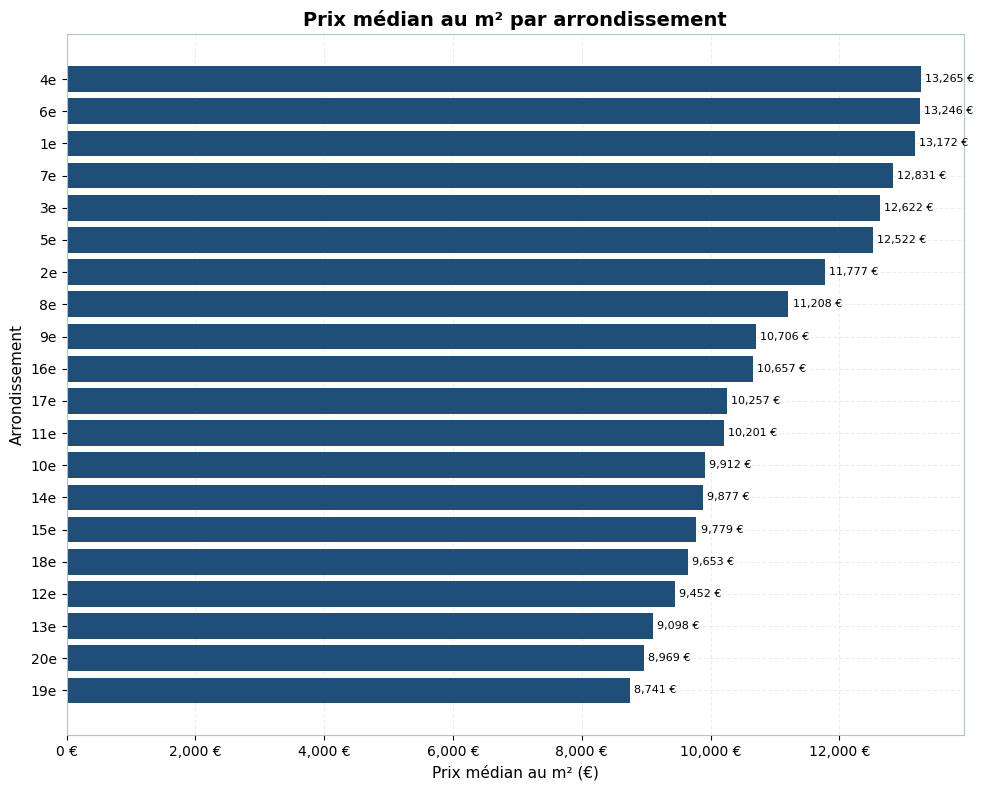

In [70]:
df_prix_median_arrondissement = (
    df_history_clean
    .dropna(subset=["code_postal", "prix_au_m2"])
    .groupby("code_postal", as_index=False)
    .agg(prix_median_m2=("prix_au_m2", "median"))
    .sort_values("prix_median_m2")
)

df_prix_median_arrondissement["arrondissement"] = (
    df_prix_median_arrondissement["code_postal"]
    .astype(int)
    .sub(75000)
    .astype(str) + "e"
)

plt.figure(figsize=(10, 8))
bars = plt.barh(
    df_prix_median_arrondissement["arrondissement"],
    df_prix_median_arrondissement["prix_median_m2"],
    color=COULEUR_PRINCIPALE
)
plt.title("Prix médian au m² par arrondissement")
plt.xlabel("Prix médian au m² (€)")
plt.ylabel("Arrondissement")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x:,.0f} €")
)
plt.bar_label(
    bars,
    labels=[f"{v:,.0f} €" for v in df_prix_median_arrondissement["prix_median_m2"]],
    padding=3,
    fontsize=8
)
plt.tight_layout()
plt.show()


## Valeurs réelles vs valeurs prédites


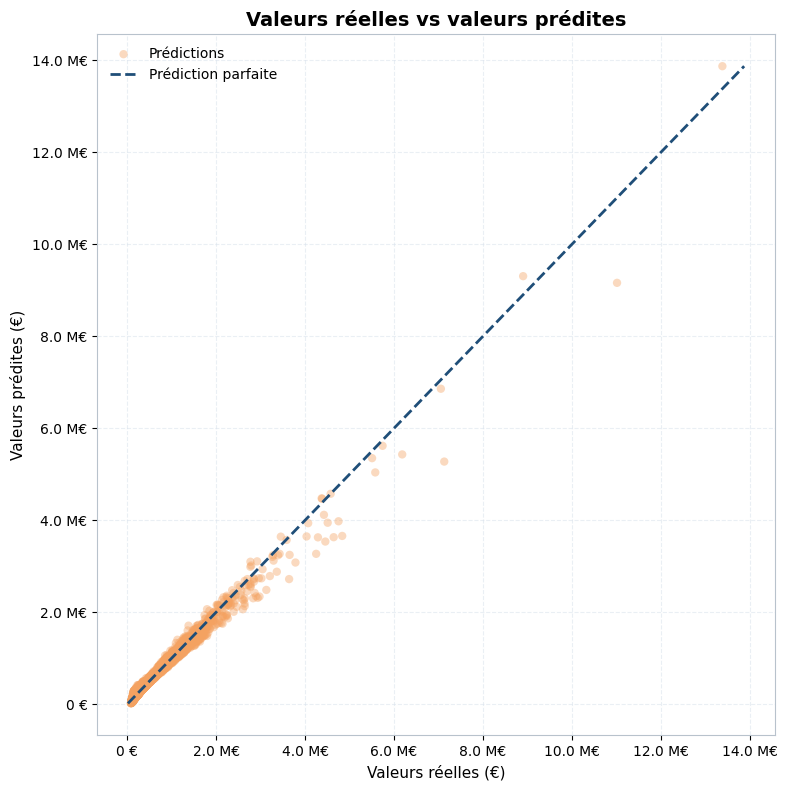

In [71]:
plt.figure(figsize=(8, 8))
plt.scatter(
    y_test,
    y_pred,
    alpha=0.40,
    color=COULEUR_PREDICTION,
    edgecolors="none",
    label="Prédictions"
)

borne_min = min(float(y_test.min()), float(np.min(y_pred)))
borne_max = max(float(y_test.max()), float(np.max(y_pred)))

plt.plot(
    [borne_min, borne_max],
    [borne_min, borne_max],
    linestyle="--",
    linewidth=2,
    color=COULEUR_PRINCIPALE,
    label="Prédiction parfaite"
)

plt.title("Valeurs réelles vs valeurs prédites")
plt.xlabel("Valeurs réelles (€)")
plt.ylabel("Valeurs prédites (€)")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f} M€" if abs(x) >= 1_000_000 else f"{x:,.0f} €")
)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f} M€" if abs(x) >= 1_000_000 else f"{x:,.0f} €")
)
plt.legend()
plt.tight_layout()
plt.show()


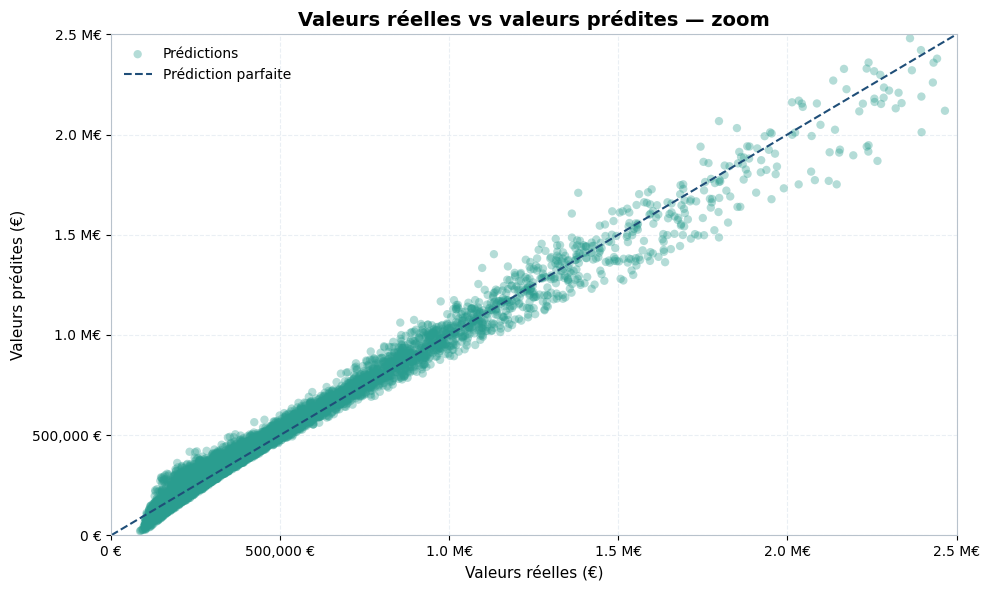

In [72]:
# Valeurs réelles vs valeurs prédites — zoom

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35,
    color=COULEUR_SECONDAIRE,
    edgecolors="none",
    label="Prédictions"
)

# Limites communes pour tracer correctement la diagonale
limite_min = 0
limite_max = 2_500_000

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    color=COULEUR_PRINCIPALE,
    label="Prédiction parfaite"
)

plt.title("Valeurs réelles vs valeurs prédites — zoom")
plt.xlabel("Valeurs réelles (€)")
plt.ylabel("Valeurs prédites (€)")

# Zoom
plt.xlim(limite_min, limite_max)
plt.ylim(limite_min, limite_max)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x / 1_000_000:.1f} M€"
        if x >= 1_000_000
        else f"{x:,.0f} €"
    )
)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x / 1_000_000:.1f} M€"
        if x >= 1_000_000
        else f"{x:,.0f} €"
    )
)

plt.legend()
plt.tight_layout()
plt.show()

## Distribution des erreurs du modèle


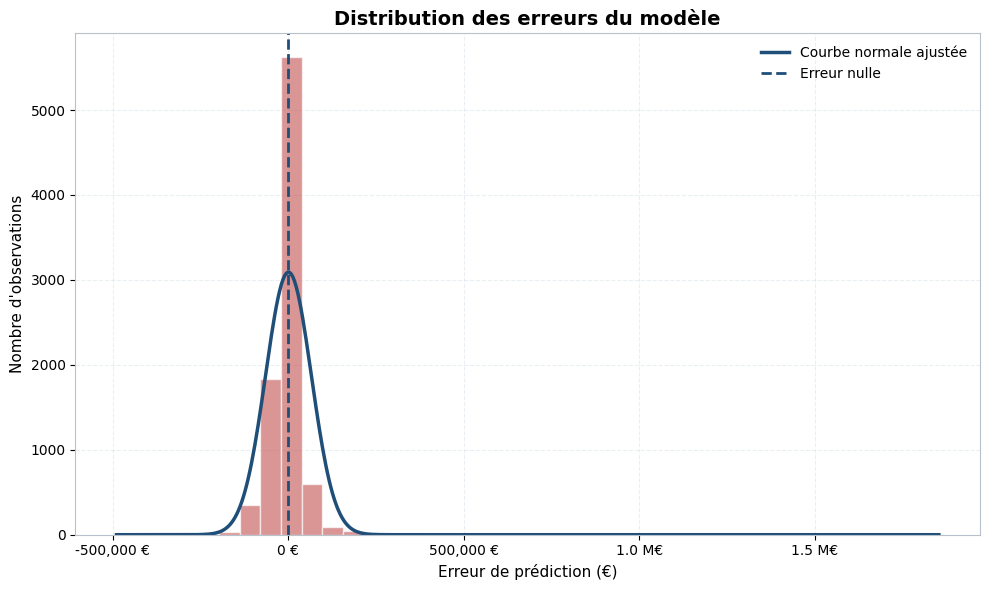

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Erreurs du modèle
erreurs = y_test - y_pred

plt.figure(figsize=(10, 6))

# Histogramme
effectifs, bornes, _ = plt.hist(
    erreurs,
    bins=40,
    alpha=0.65,
    color=COULEUR_ERREUR,
    edgecolor="white"
)


moyenne_erreurs = erreurs.mean()
ecart_type_erreurs = erreurs.std()


x = np.linspace(erreurs.min(), erreurs.max(), 500)


largeur_classe = bornes[1] - bornes[0]


courbe_normale = (
    norm.pdf(x, moyenne_erreurs, ecart_type_erreurs)
    * len(erreurs)
    * largeur_classe
)

plt.plot(
    x,
    courbe_normale,
    linewidth=2.5,
    color=COULEUR_PRINCIPALE,
    label="Courbe normale ajustée"
)


plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    color=COULEUR_PRINCIPALE,
    label="Erreur nulle"
)

plt.title("Distribution des erreurs du modèle")
plt.xlabel("Erreur de prédiction (€)")
plt.ylabel("Nombre d'observations")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.legend()
plt.tight_layout()
plt.show()

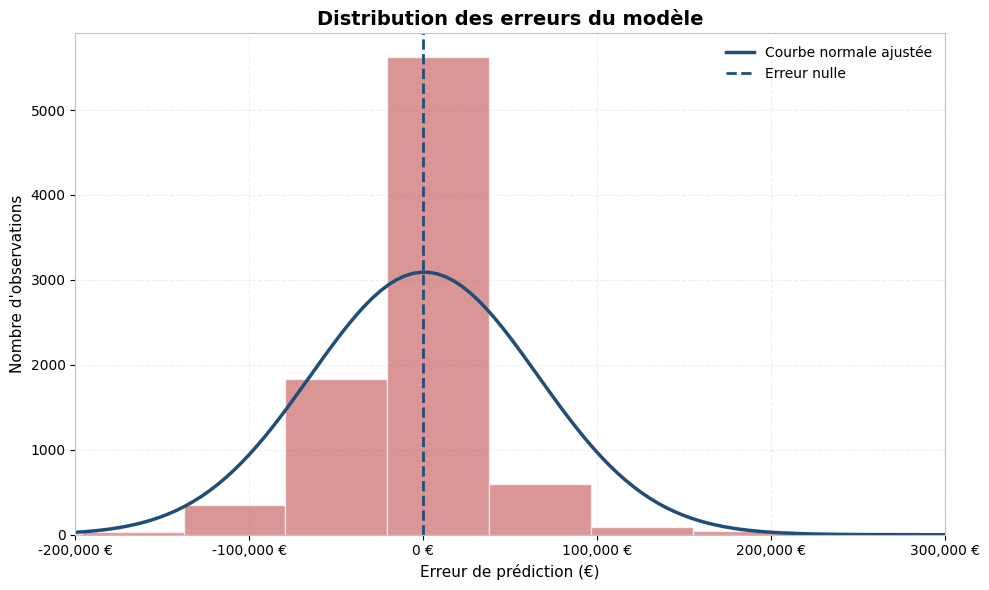

In [74]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Erreurs du modèle
erreurs = y_test - y_pred

plt.figure(figsize=(10, 6))

# Histogramme
effectifs, bornes, _ = plt.hist(
    erreurs,
    bins=40,
    alpha=0.65,
    color=COULEUR_ERREUR,
    edgecolor="white"
)

moyenne_erreurs = erreurs.mean()
ecart_type_erreurs = erreurs.std()


x = np.linspace(erreurs.min(), erreurs.max(), 500)
largeur_classe = bornes[1] - bornes[0]

courbe_normale = (
    norm.pdf(x, moyenne_erreurs, ecart_type_erreurs)
    * len(erreurs)
    * largeur_classe
)

plt.plot(
    x,
    courbe_normale,
    linewidth=2.5,
    color=COULEUR_PRINCIPALE,
    label="Courbe normale ajustée"
)

# Ligne correspondant à une erreur nulle
plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    color=COULEUR_PRINCIPALE,
    label="Erreur nulle"
)

plt.title("Distribution des erreurs du modèle")
plt.xlabel("Erreur de prédiction (€)")
plt.ylabel("Nombre d'observations")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.legend()
plt.xlim(-200_000, 300_000)
plt.tight_layout()
plt.show()

### Zoom sur la distribution des erreurs

Le graphique global met en évidence la présence de quelques erreurs de prédiction très élevées. Ces valeurs extrêmes étirent l’axe horizontal et réduisent la lisibilité de la majorité des observations.

Un zoom est donc appliqué sur la zone comprise entre -200 000 € et 300 000 €. Les erreurs situées en dehors de cet intervalle ne sont pas supprimées des données : elles sont uniquement masquées sur cette représentation.

La majorité des erreurs reste concentrée autour de 0 €, ce qui indique que le modèle produit globalement des prédictions proches des valeurs réelles. La courbe normale ajustée permet également d’évaluer la forme générale de la distribution et de repérer un éventuel biais de sous-estimation ou de surestimation.

## Valeur du portefeuille par segment


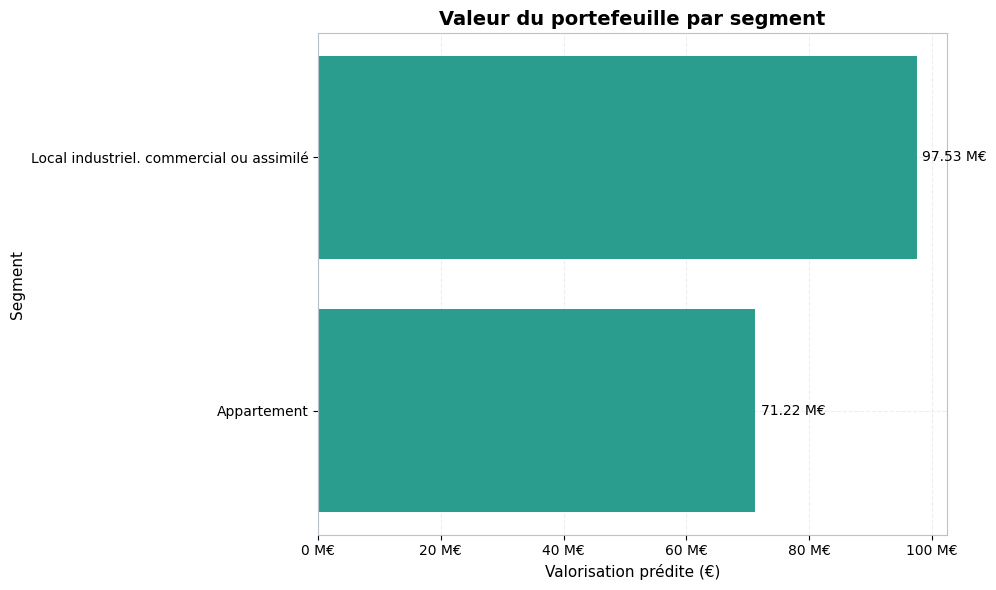

In [75]:
df_valeur_portefeuille_segment = (
    df_wallet_prediction
    .groupby("type_local", as_index=False)
    .agg(valeur_portefeuille=("valeur_fonciere_predite", "sum"))
    .sort_values("valeur_portefeuille")
)

plt.figure(figsize=(10, 6))
bars = plt.barh(
    df_valeur_portefeuille_segment["type_local"],
    df_valeur_portefeuille_segment["valeur_portefeuille"],
    color=COULEUR_SECONDAIRE
)
plt.title("Valeur du portefeuille par segment")
plt.xlabel("Valorisation prédite (€)")
plt.ylabel("Segment")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x/1_000_000:.0f} M€")
)
plt.bar_label(
    bars,
    labels=[f"{v/1_000_000:.2f} M€" for v in df_valeur_portefeuille_segment["valeur_portefeuille"]],
    padding=4
)
plt.tight_layout()
plt.show()


# Milestone 6 - Comparaison de plusieurs modèles de prédiction

Cette partie est ajoutée à la fin du notebook afin de comparer la régression linéaire déjà utilisée avec trois modèles capables de représenter des relations non linéaires :

- un arbre de décision ;
- une forêt aléatoire ;
- un modèle de Gradient Boosting.

Les mêmes jeux d'entraînement et de test sont conservés afin de garantir une comparaison équitable.

Les modèles sont évalués avec :

- la MAE, qui représente l'erreur absolue moyenne en euros ;
- la MAPE, qui représente l'erreur moyenne en pourcentage ;
- la RMSE, qui pénalise davantage les erreurs importantes ;
- le coefficient de détermination R².

In [76]:
# Importation des modèles et des métriques nécessaires
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Imports réalisés avec succès.")

Imports réalisés avec succès.


## 1. Arbre de décision

L'arbre de décision découpe progressivement les données selon les caractéristiques des biens. Il peut ainsi créer des règles basées sur la surface, la date, la localisation ou le type de local.

Contrairement à la régression linéaire, il peut représenter des relations non linéaires et des interactions entre les variables.

In [77]:
# Création et entraînement de l'arbre de décision
model_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

model_tree.fit(X_train, y_train)

# Prédictions
y_pred_tree = model_tree.predict(X_test)
y_pred_tree_train = model_tree.predict(X_train)

# Métriques sur le jeu de test
mae_tree = mean_absolute_error(y_test, y_pred_tree)
mape_tree = mean_absolute_percentage_error(y_test, y_pred_tree) * 100
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

# Métriques sur le jeu d'entraînement
mae_tree_train = mean_absolute_error(y_train, y_pred_tree_train)
r2_tree_train = r2_score(y_train, y_pred_tree_train)

print("Résultats de l'arbre de décision")
print("-" * 45)
print(f"MAE test : {mae_tree:,.2f} €")
print(f"MAPE test : {mape_tree:.2f} %")
print(f"RMSE test : {rmse_tree:,.2f} €")
print(f"R² test : {r2_tree:.3f}")
print()
print(f"MAE entraînement : {mae_tree_train:,.2f} €")
print(f"R² entraînement : {r2_tree_train:.3f}")

Résultats de l'arbre de décision
---------------------------------------------
MAE test : 40,528.44 €
MAPE test : 7.93 %
RMSE test : 109,160.40 €
R² test : 0.950

MAE entraînement : 39,821.81 €
R² entraînement : 0.865


### Interprétation de l'arbre de décision

L'arbre de décision peut capter des relations plus complexes qu'une régression linéaire. Les paramètres `max_depth=10` et `min_samples_leaf=10` limitent sa complexité afin de réduire le risque de surapprentissage.

La comparaison entre les résultats d'entraînement et de test est essentielle. Si le modèle est presque parfait sur l'entraînement mais nettement moins bon sur le test, cela signifie qu'il a mémorisé les données au lieu d'apprendre des règles généralisables.

## 2. Random Forest

La forêt aléatoire combine les prédictions de plusieurs arbres de décision. Chaque arbre est entraîné sur un échantillon légèrement différent des données.

La prédiction finale correspond à la moyenne des prédictions produites par l'ensemble des arbres, ce qui rend généralement le modèle plus stable qu'un arbre unique.

In [78]:
# Création et entraînement de la forêt aléatoire
model_forest = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model_forest.fit(X_train, y_train)

# Prédictions
y_pred_forest = model_forest.predict(X_test)
y_pred_forest_train = model_forest.predict(X_train)

# Métriques sur le jeu de test
mae_forest = mean_absolute_error(y_test, y_pred_forest)
mape_forest = mean_absolute_percentage_error(y_test, y_pred_forest) * 100
rmse_forest = np.sqrt(mean_squared_error(y_test, y_pred_forest))
r2_forest = r2_score(y_test, y_pred_forest)

# Métriques sur le jeu d'entraînement
mae_forest_train = mean_absolute_error(y_train, y_pred_forest_train)
r2_forest_train = r2_score(y_train, y_pred_forest_train)

print("Résultats de la forêt aléatoire")
print("-" * 45)
print(f"MAE test : {mae_forest:,.2f} €")
print(f"MAPE test : {mape_forest:.2f} %")
print(f"RMSE test : {rmse_forest:,.2f} €")
print(f"R² test : {r2_forest:.3f}")
print()
print(f"MAE entraînement : {mae_forest_train:,.2f} €")
print(f"R² entraînement : {r2_forest_train:.3f}")

Résultats de la forêt aléatoire
---------------------------------------------
MAE test : 17,955.65 €
MAPE test : 2.54 %
RMSE test : 78,965.17 €
R² test : 0.974

MAE entraînement : 12,616.22 €
R² entraînement : 0.940


### Interprétation de la forêt aléatoire

La forêt aléatoire est généralement plus robuste qu'un arbre de décision isolé, car elle moyenne les résultats de nombreux arbres.

Elle peut représenter des relations non linéaires et détecter des interactions entre la surface, la localisation, la date et le type de local. Elle est toutefois moins simple à interpréter qu'une régression linéaire et demande davantage de ressources de calcul.

Un écart raisonnable entre les performances d'entraînement et de test indique une bonne capacité de généralisation. Un écart très important signalerait un surapprentissage.

,Variable,Importance
0,surface_reelle,0.98
1,date_numerique,0.01
2,code_postal_75006,0.00
3,code_postal_75007,0.00
4,code_postal_75004,0.00
5,code_postal_75003,0.00
6,code_postal_75001,0.00
7,code_postal_75005,0.00
8,type_local_Local industriel. commercial ou ass...,0.00
9,type_local_Appartement,0.00


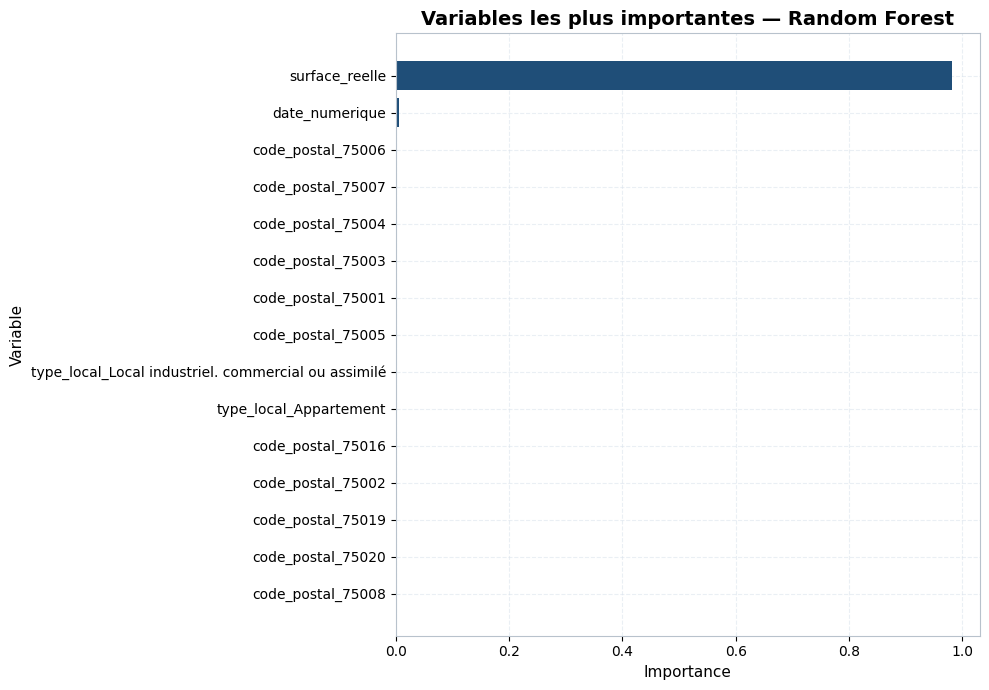

In [79]:
# Importance des variables de la forêt aléatoire
df_importance_forest = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": model_forest.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(df_importance_forest.head(15))

top_importance_forest = (
    df_importance_forest.head(15)
    .sort_values(by="Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_importance_forest["Variable"],
    top_importance_forest["Importance"],
    color=COULEUR_PRINCIPALE
)

plt.title("Variables les plus importantes — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

### Importance des variables dans la forêt aléatoire

Ce graphique montre quelles variables ont le plus contribué aux décisions prises par les arbres.

Une importance élevée signifie que la variable a souvent permis de réduire les erreurs de prédiction. Cette importance ne prouve toutefois pas un lien de causalité.

Lorsque plusieurs variables contiennent des informations proches, leur importance peut également être répartie entre elles.

## 3. Gradient Boosting

Le Gradient Boosting construit plusieurs arbres successivement. Chaque nouvel arbre cherche à corriger les erreurs produites par les arbres précédents.

Cette méthode est souvent performante sur les données tabulaires, car elle peut représenter des relations non linéaires et des interactions complexes entre les variables.

In [80]:
# Création et entraînement du Gradient Boosting
model_gradient = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

model_gradient.fit(X_train, y_train)

# Prédictions
y_pred_gradient = model_gradient.predict(X_test)
y_pred_gradient_train = model_gradient.predict(X_train)

# Métriques sur le jeu de test
mae_gradient = mean_absolute_error(y_test, y_pred_gradient)
mape_gradient = mean_absolute_percentage_error(y_test, y_pred_gradient) * 100
rmse_gradient = np.sqrt(mean_squared_error(y_test, y_pred_gradient))
r2_gradient = r2_score(y_test, y_pred_gradient)

# Métriques sur le jeu d'entraînement
mae_gradient_train = mean_absolute_error(y_train, y_pred_gradient_train)
r2_gradient_train = r2_score(y_train, y_pred_gradient_train)

print("Résultats du Gradient Boosting")
print("-" * 45)
print(f"MAE test : {mae_gradient:,.2f} €")
print(f"MAPE test : {mape_gradient:.2f} %")
print(f"RMSE test : {rmse_gradient:,.2f} €")
print(f"R² test : {r2_gradient:.3f}")
print()
print(f"MAE entraînement : {mae_gradient_train:,.2f} €")
print(f"R² entraînement : {r2_gradient_train:.3f}")

Résultats du Gradient Boosting
---------------------------------------------
MAE test : 21,053.08 €
MAPE test : 3.99 %
RMSE test : 57,030.06 €
R² test : 0.986

MAE entraînement : 19,825.19 €
R² entraînement : 0.997


### Interprétation du Gradient Boosting

Le Gradient Boosting améliore progressivement ses prédictions en corrigeant les erreurs des arbres précédents.

Le paramètre `learning_rate=0.05` ralentit l'apprentissage afin que chaque arbre apporte une correction limitée. La profondeur des arbres est fixée à 3 afin de conserver des arbres simples.

Cette méthode peut être très performante, mais elle est sensible au choix de ses paramètres. La comparaison entre les performances d'entraînement et de test permet de vérifier qu'elle ne surapprend pas.

## 4. Comparaison finale des modèles

Les quatre modèles sont maintenant comparés sur exactement le même jeu de test :

- la régression linéaire ;
- l'arbre de décision ;
- la forêt aléatoire ;
- le Gradient Boosting.

In [81]:
# Calcul de la RMSE du modèle linéaire déjà entraîné
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred))

# Tableau de comparaison
df_comparaison_modeles = pd.DataFrame({
    "Modèle": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE (€)": [
        mae,
        mae_tree,
        mae_forest,
        mae_gradient
    ],
    "MAPE (%)": [
        mape,
        mape_tree,
        mape_forest,
        mape_gradient
    ],
    "RMSE (€)": [
        rmse_linear,
        rmse_tree,
        rmse_forest,
        rmse_gradient
    ],
    "R²": [
        r2,
        r2_tree,
        r2_forest,
        r2_gradient
    ]
}).sort_values(
    by="MAE (€)",
    ascending=True
).reset_index(drop=True)

display(
    df_comparaison_modeles.style.format({
        "MAE (€)": "{:,.2f} €",
        "MAPE (%)": "{:.2f} %",
        "RMSE (€)": "{:,.2f} €",
        "R²": "{:.3f}"
    })
)

,Modèle,MAE (€),MAPE (%),RMSE (€),R²
0,Random Forest,"17,955.65 €",2.54 %,"78,965.17 €",0.974
1,Gradient Boosting,"21,053.08 €",3.99 %,"57,030.06 €",0.986
2,Linear Regression,"32,821.64 €",9.05 %,"65,290.48 €",0.982
3,Decision Tree,"40,528.44 €",7.93 %,"109,160.40 €",0.950


### Interprétation de la comparaison

Le modèle présentant les valeurs de MAE, MAPE et RMSE les plus faibles commet les erreurs les moins importantes.

Le R² doit être le plus proche possible de 1. Il ne doit toutefois pas être utilisé seul : un modèle peut présenter un R² élevé tout en produisant des erreurs importantes sur certains biens.

Le choix final doit également prendre en compte :

- la stabilité entre les résultats d'entraînement et de test ;
- la capacité de généralisation ;
- le niveau d'interprétabilité ;
- le coût de calcul ;
- l'amélioration réelle apportée par rapport à la régression linéaire.

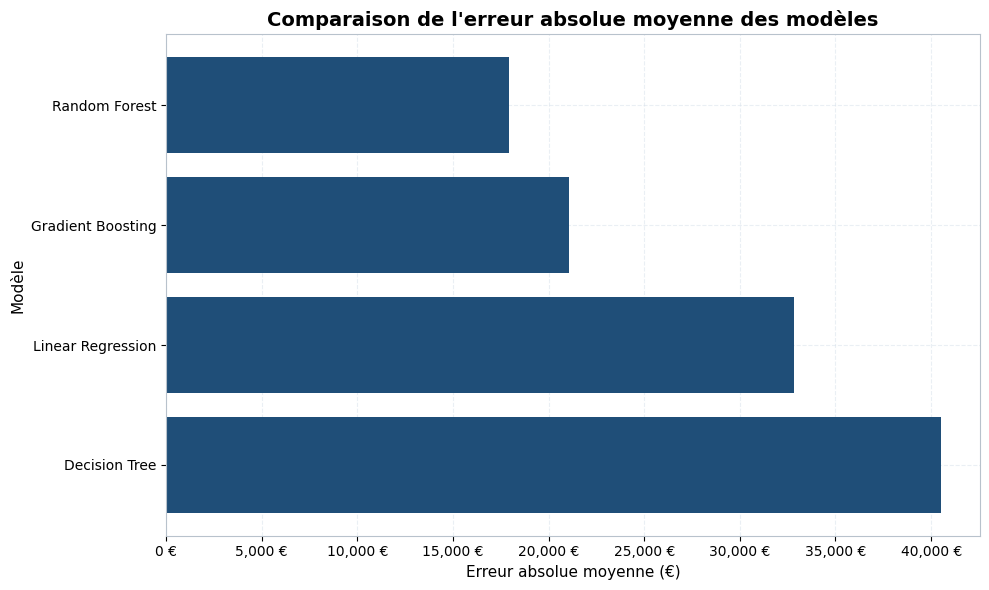

In [82]:
# Comparaison graphique de la MAE
df_graph_mae = df_comparaison_modeles.sort_values(
    by="MAE (€)",
    ascending=False
)

plt.figure(figsize=(10, 6))
plt.barh(
    df_graph_mae["Modèle"],
    df_graph_mae["MAE (€)"],
    color=COULEUR_PRINCIPALE
)

plt.title("Comparaison de l'erreur absolue moyenne des modèles")
plt.xlabel("Erreur absolue moyenne (€)")
plt.ylabel("Modèle")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x:,.0f} €")
)

plt.tight_layout()
plt.show()

### Comparaison de l'erreur absolue moyenne

La MAE représente l'écart absolu moyen entre la valeur réelle et la valeur prédite.

Le modèle présentant la barre la plus courte commet, en moyenne, les erreurs les plus faibles sur le jeu de test.

Cette métrique doit être complétée par la MAPE, la RMSE, le R² et la comparaison entre entraînement et test.

In [83]:
# Sélection automatique du meilleur modèle selon la MAE
predictions_modeles = {
    "Linear Regression": y_pred,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest,
    "Gradient Boosting": y_pred_gradient
}

nom_meilleur_modele = df_comparaison_modeles.loc[0, "Modèle"]
y_pred_meilleur = predictions_modeles[nom_meilleur_modele]

print("Meilleur modèle selon la MAE :", nom_meilleur_modele)

Meilleur modèle selon la MAE : Random Forest


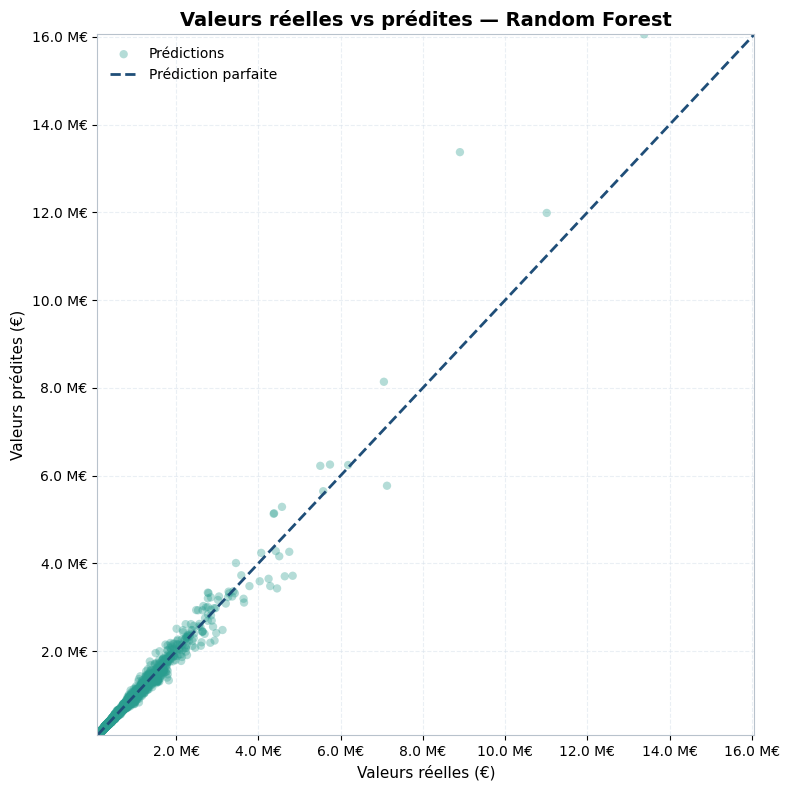

In [84]:
# Valeurs réelles contre valeurs prédites du meilleur modèle
plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_pred_meilleur,
    alpha=0.35,
    color=COULEUR_SECONDAIRE,
    edgecolors="none",
    label="Prédictions"
)

limite_min = min(float(y_test.min()), float(np.min(y_pred_meilleur)))
limite_max = max(float(y_test.max()), float(np.max(y_pred_meilleur)))

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    linewidth=2,
    color=COULEUR_PRINCIPALE,
    label="Prédiction parfaite"
)

plt.title(f"Valeurs réelles vs prédites — {nom_meilleur_modele}")
plt.xlabel("Valeurs réelles (€)")
plt.ylabel("Valeurs prédites (€)")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.xlim(limite_min, limite_max)
plt.ylim(limite_min, limite_max)
plt.legend()
plt.tight_layout()
plt.show()

### Valeurs réelles et valeurs prédites par le meilleur modèle

La diagonale représente une prédiction parfaite.

Les points situés au-dessus de la diagonale correspondent à des surestimations, tandis que les points situés en dessous correspondent à des sous-estimations.

Plus les points sont proches de la diagonale, plus les prédictions du modèle sont proches des valeurs réelles.

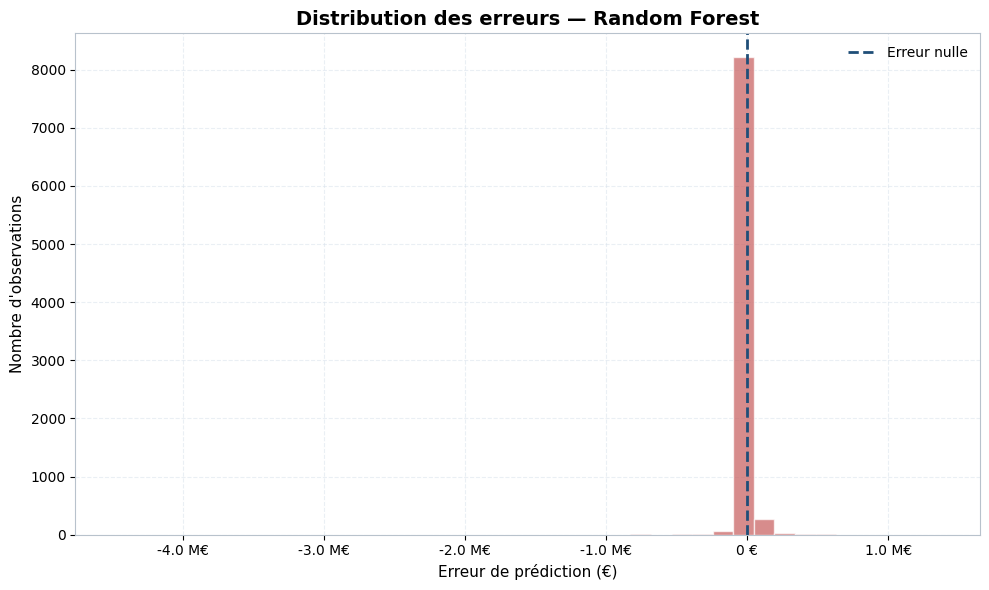

In [85]:
# Distribution des erreurs du meilleur modèle
erreurs_meilleur_modele = y_test.to_numpy() - y_pred_meilleur

plt.figure(figsize=(10, 6))

plt.hist(
    erreurs_meilleur_modele,
    bins=40,
    alpha=0.70,
    color=COULEUR_ERREUR,
    edgecolor="white"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    color=COULEUR_PRINCIPALE,
    label="Erreur nulle"
)

plt.title(f"Distribution des erreurs — {nom_meilleur_modele}")
plt.xlabel("Erreur de prédiction (€)")
plt.ylabel("Nombre d'observations")

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: (
            f"{x / 1_000_000:.1f} M€"
            if abs(x) >= 1_000_000
            else f"{x:,.0f} €"
        )
    )
)

plt.legend()
plt.tight_layout()
plt.show()

### Distribution des erreurs du meilleur modèle

Une erreur proche de zéro correspond à une prédiction précise.

Une erreur positive indique que le modèle a sous-estimé la valeur réelle. Une erreur négative indique qu'il l'a surestimée.

Une distribution concentrée autour de zéro est recherchée. La présence de valeurs très éloignées de zéro montre que le modèle rencontre davantage de difficultés sur certains biens atypiques ou de très forte valeur.

# Contrôle final automatique des résultats

Cette section vérifie la cohérence technique des données, des prédictions, de la valorisation du portefeuille, de la classification KMeans et de la comparaison des modèles.

Un statut **OK** confirme que le contrôle technique est satisfait. Il ne remplace pas l'interprétation métier ni une validation temporelle sur des données réellement futures.

In [86]:
# Contrôles automatiques de cohérence
controles = []

def ajouter_controle(nom, condition, detail):
    controles.append({
        "Contrôle": nom,
        "Statut": "OK" if bool(condition) else "À vérifier",
        "Détail": detail
    })

# Données historiques
ajouter_controle(
    "Aucune valeur manquante dans l'historique nettoyé",
    df_history_clean.isna().sum().sum() == 0,
    f"{int(df_history_clean.isna().sum().sum())} valeur(s) manquante(s)"
)

ajouter_controle(
    "Aucun doublon complet dans l'historique nettoyé",
    df_history_clean.duplicated().sum() == 0,
    f"{int(df_history_clean.duplicated().sum())} doublon(s)"
)

ajouter_controle(
    "Surfaces et valeurs foncières strictement positives",
    ((df_history_clean["surface_reelle"] > 0).all()
     and (df_history_clean["valeur_fonciere"] > 0).all()),
    "Contrôle des valeurs nulles ou négatives"
)

# Jeux d'entraînement et de test
ajouter_controle(
    "Même nombre de lignes entre X et y",
    len(X) == len(y),
    f"X={len(X):,} ; y={len(y):,}"
)

ajouter_controle(
    "Découpage entraînement/test complet",
    len(X_train) + len(X_test) == len(X),
    f"train={len(X_train):,} ; test={len(X_test):,} ; total={len(X):,}"
)

# Prédictions des quatre modèles
predictions_a_controler = {
    "Régression linéaire": y_pred,
    "Arbre de décision": y_pred_tree,
    "Forêt aléatoire": y_pred_forest,
    "Gradient Boosting": y_pred_gradient
}

for nom_modele, predictions in predictions_a_controler.items():
    predictions_array = np.asarray(predictions)
    ajouter_controle(
        f"Prédictions valides — {nom_modele}",
        (len(predictions_array) == len(y_test)
         and np.isfinite(predictions_array).all()),
        f"{len(predictions_array):,} prédiction(s) pour {len(y_test):,} observations"
    )

# Portefeuille
total_portefeuille = df_wallet_prediction["valeur_fonciere_predite"].sum()
total_segments = valorisation_par_segment["valorisation_predite"].sum()

ajouter_controle(
    "Somme des segments égale à la valorisation totale",
    np.isclose(total_portefeuille, total_segments),
    f"Total={total_portefeuille/1_000_000:.2f} M€ ; segments={total_segments/1_000_000:.2f} M€"
)

ajouter_controle(
    "Aucune valorisation prédite négative",
    (df_wallet_prediction["valeur_fonciere_predite"] >= 0).all(),
    f"Minimum prédit={df_wallet_prediction['valeur_fonciere_predite'].min():,.2f} €"
)

# KMeans
ajouter_controle(
    "KMeans produit exactement deux clusters",
    df_classification["cluster"].nunique() == 2,
    f"{df_classification['cluster'].nunique()} cluster(s)"
)

ajouter_controle(
    "Toutes les observations KMeans sont labellisées",
    df_classification["type_local_predit"].notna().all(),
    f"{int(df_classification['type_local_predit'].isna().sum())} libellé(s) manquant(s)"
)

ajouter_controle(
    "Score de silhouette dans son intervalle valide",
    -1 <= score_silhouette <= 1,
    f"Score={score_silhouette:.3f}"
)

df_controles = pd.DataFrame(controles)
display(df_controles)

print("\nRésumé :")
print(df_controles["Statut"].value_counts())


,Contrôle,Statut,Détail
0,Aucune valeur manquante dans l'historique nettoyé,OK,0 valeur(s) manquante(s)
1,Aucun doublon complet dans l'historique nettoyé,OK,0 doublon(s)
2,Surfaces et valeurs foncières strictement posi...,OK,Contrôle des valeurs nulles ou négatives
3,Même nombre de lignes entre X et y,OK,"X=26,180 ; y=26,180"
4,Découpage entraînement/test complet,OK,"train=17,540 ; test=8,640 ; total=26,180"
5,Prédictions valides — Régression linéaire,OK,"8,640 prédiction(s) pour 8,640 observations"
6,Prédictions valides — Arbre de décision,OK,"8,640 prédiction(s) pour 8,640 observations"
7,Prédictions valides — Forêt aléatoire,OK,"8,640 prédiction(s) pour 8,640 observations"
8,Prédictions valides — Gradient Boosting,OK,"8,640 prédiction(s) pour 8,640 observations"
9,Somme des segments égale à la valorisation totale,OK,Total=168.75 M€ ; segments=168.75 M€



Résumé :
Statut
OK    14
Name: count, dtype: int64


## Contrôle de la généralisation des modèles

Le tableau suivant compare les performances d'entraînement et de test. Une forte dégradation sur le jeu de test peut signaler un surapprentissage.

Un résultat test légèrement meilleur que le résultat d'entraînement reste possible lorsque les deux jeux ne présentent pas exactement la même dispersion. Il est donc préférable de compléter ce contrôle par une validation croisée et, pour une prédiction au 31 décembre 2022, par une validation chronologique.

In [87]:
# Tableau de généralisation entraînement / test
y_pred_linear_train = model_linear.predict(X_train)

df_generalisation = pd.DataFrame({
    "Modèle": [
        "Régression linéaire",
        "Arbre de décision",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE entraînement (€)": [
        mean_absolute_error(y_train, y_pred_linear_train),
        mae_tree_train,
        mae_forest_train,
        mae_gradient_train
    ],
    "MAE test (€)": [
        mae,
        mae_tree,
        mae_forest,
        mae_gradient
    ],
    "R² entraînement": [
        r2_score(y_train, y_pred_linear_train),
        r2_tree_train,
        r2_forest_train,
        r2_gradient_train
    ],
    "R² test": [
        r2,
        r2_tree,
        r2_forest,
        r2_gradient
    ]
})

df_generalisation["Écart MAE test - entraînement (€)"] = (
    df_generalisation["MAE test (€)"]
    - df_generalisation["MAE entraînement (€)"]
)

df_generalisation["Écart R² entraînement - test"] = (
    df_generalisation["R² entraînement"]
    - df_generalisation["R² test"]
)

display(
    df_generalisation.style.format({
        "MAE entraînement (€)": "{:,.2f} €",
        "MAE test (€)": "{:,.2f} €",
        "R² entraînement": "{:.3f}",
        "R² test": "{:.3f}",
        "Écart MAE test - entraînement (€)": "{:,.2f} €",
        "Écart R² entraînement - test": "{:.3f}"
    })
)


,Modèle,MAE entraînement (€),MAE test (€),R² entraînement,R² test,Écart MAE test - entraînement (€),Écart R² entraînement - test
0,Régression linéaire,"34,527.54 €","32,821.64 €",0.982,0.982,"-1,705.90 €",-0.001
1,Arbre de décision,"39,821.81 €","40,528.44 €",0.865,0.950,706.63 €,-0.085
2,Random Forest,"12,616.22 €","17,955.65 €",0.940,0.974,"5,339.43 €",-0.034
3,Gradient Boosting,"19,825.19 €","21,053.08 €",0.997,0.986,"1,227.89 €",0.010


## Limite méthodologique 

Le découpage actuel est aléatoire : les jeux d'entraînement et de test contiennent tous les deux des transactions réparties entre 2017 et 2021. Cette méthode mesure correctement la capacité du modèle à prédire d'autres transactions issues de la même période.

En revanche, la valorisation du portefeuille est réalisée au 31 décembre 2022, donc au-delà de la période historique. Une validation chronologique — entraînement sur les années les plus anciennes puis test sur l'année la plus récente — serait plus exigeante et plus proche du cadre réel d'utilisation.

Les modèles à base d'arbres sont très efficaces pour interpoler dans les situations déjà observées, mais ils extrapolent moins naturellement une tendance temporelle au-delà de la période d'entraînement. Le choix du modèle final doit donc tenir compte non seulement de la MAE, de la MAPE, de la RMSE et du R², mais aussi de la date réelle à laquelle les prédictions seront utilisées.